# Modul 5 — Normalisasi, Standarisasi, dan Encoding

**Praktikum Data Wrangling (SD25-20007) · Program Studi Sains Data ITERA**

Workbench menyimpan notebook ini di laptop sebagai **`dw-module-05/05_skala.ipynb`**; seluruh
keluaran modul ditulis ke folder `dw-module-05/` itu. Modul ini membaca keluaran acuan Modul 4
yang disediakan di **`data/acuan/`**: `transaksi_m04.parquet`, `pelanggan_m04.parquet`, dan
`produk_m04.parquet` (bukan keluaran Modul 4 Anda sendiri, sehingga kesalahan di Modul 4 tidak
terbawa ke sini). Unduh `data-acuan-modul-05.zip` di halaman modul dan ekstrak di folder `data-wrangling/`; isinya masuk ke `data/acuan/`. Buku ajar: Bab 6.

| Bagian | Isi notebook ini | Dinilai? |
|---|---|---|
| A–D Prosedur terbimbing | **kode lengkap dan pembahasan** | dijalankan dan lulus checkpoint |
| Latihan 5.1–5.2 | kerangka `TODO` | **ya** — *Latihan Mandiri di Lab* (20% nilai modul) |
| Tugas Individu | kerangka `TODO` | **ya** — *Tugas Individu* (80% nilai modul) |

Bagian A–D bukan untuk disalin tanpa dibaca. Latihan dan tugas memakai **cara berpikir yang
sama** pada pertanyaan lain (algoritma mana yang peka terhadap skala, encoding mana yang cocok
untuk model mana, apakah parameter tersimpan cukup untuk mengulang transformasi), dan pertanyaan
analisis menanyakan alasan di balik setiap langkah A–D.

**Aturan main**
1. `data/raw/` dan `data/acuan/` bersifat *read-only* — jangan menulis ke sana.
2. Setiap parameter transformasi dipelajari dari bagian **latih** saja, lalu diterapkan ke bagian uji.
3. Kolom fitur mentah tidak ditimpa: hasil transformasi ditulis ke kolom baru berawalan `t_`.
4. Setiap keputusan dicatat pada `log-keputusan.csv` di akar workspace (`K-05-xxx`).
5. Sebelum mengumpulkan: *Kernel → Restart Kernel and Run All Cells*, lalu jalankan Checkpoint.

## Bagian A — Fitur pada butir yang benar, lalu profil skalanya

### A.1 Menyiapkan notebook

In [1]:
import json
import shutil
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

# Kernel DSWorkbench menjalankan sel di luar thread utama, sehingga backend GUI
# (mis. "macosx") gagal membuat figure. Di luar Jupyter/ipykernel dipakai Agg;
# figure yang terbuka tetap ditampilkan kernel sebagai gambar di bawah sel.
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
    warnings.filterwarnings("ignore", message=r"FigureCanvas\w* is non-interactive")
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
from sklearn.preprocessing import (FunctionTransformer, LabelEncoder, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, RobustScaler, StandardScaler, TargetEncoder)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "raw").is_dir()), None)
if ROOT is None:   # dataset mentah belum disiapkan di laptop ini
    raise FileNotFoundError(
        "Folder data/raw/ (dataset mentah) belum ada di folder data-wrangling/. Di aplikasi "
        "DSWorkbench, nyalakan Local Runner lalu tekan Siapkan berkas modul pada modul ini; "
        "dataset disiapkan ke data/raw/. Setelah itu jalankan ulang sel ini.")
M04 = ROOT / "data" / "acuan"   # keluaran acuan Modul 4 (disediakan)
MODUL = ROOT / "dw-module-05"      # folder tempat Workbench menyimpan notebook ini
LOG = ROOT / "log-keputusan.csv"
OUT = MODUL / "keluaran"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 2026
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

MASUKAN = ["transaksi_m04.parquet", "pelanggan_m04.parquet", "produk_m04.parquet"]
kurang = [n for n in MASUKAN if not (M04 / n).exists()]
if kurang:
    raise FileNotFoundError(f"Belum ada di {M04}: {', '.join(kurang)}. "
                            "Unduh data-acuan-modul-05.zip di halaman modul dan ekstrak di folder data-wrangling/.")
t4 = pd.read_parquet(M04 / "transaksi_m04.parquet")
pelanggan = pd.read_parquet(M04 / "pelanggan_m04.parquet")
produk = pd.read_parquet(M04 / "produk_m04.parquet")
assert not t4.duplicated(["id_pesanan", "baris_ke"]).any(), "kunci (id_pesanan, baris_ke) tidak unik; periksa Modul 4"
assert produk.kode_produk.is_unique and pelanggan.id_pelanggan.is_unique
print("Akar repositori :", ROOT.name)
print("transaksi_m04   :", t4.shape, "| pelanggan_m04:", pelanggan.shape, "| produk_m04:", produk.shape)

Akar repositori : data-wrangling
transaksi_m04   : (24000, 46) | pelanggan_m04: (5760, 18) | produk_m04: (850, 15)


In [2]:
def angka(x: float, d: int = 1) -> str:
    """Angka berformat Indonesia untuk teks bukti: 90.66 -> '90,7'."""
    return f"{x:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")


B: dict = {}     # bukti: angka yang dikutip log keputusan dan laporan, selalu dari variabel

### A.2 Pembagian waktu dan populasi

Pembagian latih–uji ditetapkan **sebelum** fitur dihitung. Waktu sebuah pesanan adalah waktu
paling awal di antara baris-barisnya (kontrak keluaran Modul 4), bukan waktu tiap baris.

In [3]:
BATAS = pd.Timestamp("2026-04-01")      # latih: pesanan sebelum BATAS; uji: sejak BATAS
JENDELA = {"latih": (pd.Timestamp("2025-01-01"), pd.Timestamp("2026-03-31")),
           "uji": (pd.Timestamp("2026-04-01"), pd.Timestamp("2026-06-30"))}
STATUS_OMZET = ["selesai"]                       # pesanan yang dihitung sebagai pembelian
STATUS_BATAL = ["dibatalkan", "dikembalikan"]    # dihitung terpisah sebagai nilai_batal

t = t4.merge(produk[["kode_produk", "kategori"]], on="kode_produk", how="left", validate="m:1")
assert len(t) == len(t4), "join ke produk tidak boleh menambah baris"
t["waktu_pesanan"] = t.groupby("id_pesanan").waktu_wib.transform("min")
t["bagian"] = np.where(t.waktu_pesanan < BATAS, "latih", "uji")
t.loc[t.waktu_pesanan.isna(), "bagian"] = pd.NA
print(t.bagian.value_counts(dropna=False).to_string())

bagian
latih    19130
uji       4862
NaN          8


In [4]:
B["baris"], B["pesanan"] = len(t), int(t.id_pesanan.nunique())
B["baris_nat"] = int(t.waktu_wib.isna().sum())
B["baris_nat_pulih"] = int((t.waktu_wib.isna() & t.waktu_pesanan.notna()).sum())
B["pesanan_tanpa_waktu"] = int(t[t.waktu_pesanan.isna()].id_pesanan.nunique())
B["baris_tanpa_waktu"] = int(t.waktu_pesanan.isna().sum())
konstan = t.groupby("id_pesanan")[["status", "kanal", "metode_bayar"]].nunique().max().to_dict()
konstan["id_entitas"] = int(t.groupby("id_pesanan").id_entitas.nunique(dropna=False).max())
konstan["bagian"] = int(t.groupby("id_pesanan").bagian.nunique(dropna=False).max())
B["konstan_per_pesanan"] = konstan
B["baris_tamu"] = int(t.id_entitas.isna().sum())
B["pesanan_tamu"] = int(t[t.id_entitas.isna()].id_pesanan.nunique())
B["rentang"] = {b: (str(g.waktu_pesanan.min())[:16], str(g.waktu_pesanan.max())[:16]) for b, g in t.groupby("bagian")}
B["baris_per_bagian"] = t.bagian.value_counts().to_dict()
for k in ["baris", "pesanan", "baris_nat", "baris_nat_pulih", "pesanan_tanpa_waktu", "baris_tanpa_waktu",
          "konstan_per_pesanan", "baris_tamu", "pesanan_tamu", "rentang", "baris_per_bagian"]:
    print(f"{k:<22}: {B[k]}")

baris                 : 24000
pesanan               : 15744
baris_nat             : 18
baris_nat_pulih       : 10
pesanan_tanpa_waktu   : 8
baris_tanpa_waktu     : 8
konstan_per_pesanan   : {'status': 1, 'kanal': 1, 'metode_bayar': 1, 'id_entitas': 1, 'bagian': 1}
baris_tamu            : 411
pesanan_tamu          : 268
rentang               : {'latih': ('2025-01-01 00:18', '2026-03-31 22:55'), 'uji': ('2026-04-01 01:29', '2026-06-30 23:15')}
baris_per_bagian      : {'latih': 19130, 'uji': 4862}


### A.3 Fitur per entitas pelanggan

Satu baris fitur = satu entitas pelanggan pada satu bagian. Definisi setiap fitur ada pada Tabel 5.3
naskah. `teratas()` memilih nilai dengan total belanja terbesar; bila seri, urutan abjad yang menang
agar hasilnya tetap sama setiap kali dijalankan.

In [5]:
NUMERIK = ["frekuensi", "omzet", "nilai_rata_pesanan", "jumlah_unit", "n_kategori",
           "rata_diskon", "nilai_batal", "recency_hari"]
KATEGORIK = ["kanal", "kategori_favorit", "metode_bayar_utama", "provinsi", "kelompok_usia", "produk_favorit"]
TAHUN_ACUAN = 2026
URUTAN_USIA = ["<25", "25-34", "35-44", "45+"]

# Atribut entitas dari pelanggan_m04: satu entitas dapat memiliki beberapa id sumber.
assert pelanggan.groupby("id_entitas")[["provinsi", "tahun_lahir"]].nunique().max().max() == 1, \
    "provinsi/tahun_lahir berbeda antar-id dalam satu entitas; tetapkan aturan pemilihannya"
atribut = pelanggan.groupby("id_entitas").agg(provinsi=("provinsi", "first"), tahun_lahir=("tahun_lahir", "min"))
usia = (TAHUN_ACUAN - atribut.tahun_lahir).astype("float64")
atribut["kelompok_usia"] = (pd.cut(usia, [0, 24, 34, 44, 200], labels=URUTAN_USIA).astype(object)
                            .where(usia.notna(), "tidak_diketahui").astype("str"))
atribut = atribut.drop(columns="tahun_lahir")


def teratas(df: pd.DataFrame, kolom: str) -> pd.Series:
    """Nilai `kolom` dengan total_bayar terbesar per entitas; seri diputus menurut abjad."""
    s = df.groupby(["id_entitas", kolom]).total_bayar.sum().reset_index()
    s = s.sort_values(["id_entitas", "total_bayar", kolom], ascending=[True, False, True])
    return s.drop_duplicates("id_entitas").set_index("id_entitas")[kolom]

In [6]:
def bangun_fitur(t: pd.DataFrame, bagian: str) -> pd.DataFrame:
    """Fitur per entitas dari pesanan pada satu bagian (Tabel 5.3)."""
    awal, akhir = JENDELA[bagian]
    d = t[t.bagian.eq(bagian) & t.id_entitas.notna()]
    s = d[d.status.isin(STATUS_OMZET)]
    g = s.groupby("id_entitas")
    f = pd.DataFrame({
        "frekuensi": g.id_pesanan.nunique(),                 # butir pesanan, bukan baris pesanan
        "omzet": g.total_bayar.sum(),                        # total_bayar sudah memuat ongkir baris itu
        "jumlah_unit": g.jumlah.sum().astype("int64"),       # jumlah kosong (1 baris) dilewati sum()
        "n_kategori": g.kategori.nunique(),                  # kategori produk tak dikenal tidak dihitung
        "rata_diskon": g.diskon_persen.mean(),
        "recency_hari": (akhir - g.waktu_pesanan.max().dt.normalize()).dt.days,
        "ada_grosir": g.pembelian_grosir.any(),
    })
    f["nilai_rata_pesanan"] = f.omzet / f.frekuensi
    f["nilai_batal"] = (d[d.status.isin(STATUS_BATAL)].groupby("id_entitas").total_bayar.sum()
                        .reindex(f.index).fillna(0.0))
    f["kanal"] = g.kanal.first().where(g.kanal.nunique().eq(1), "keduanya")
    f["kategori_favorit"] = teratas(s, "kategori").reindex(f.index).fillna("Tidak dikenal")
    f["metode_bayar_utama"] = teratas(s, "metode_bayar")
    f["produk_favorit"] = teratas(s, "kode_produk")
    f = f.join(atribut)
    f.insert(0, "bagian", bagian)
    return f.reset_index()[["id_entitas", "bagian", *NUMERIK, "ada_grosir", *KATEGORIK]]


fitur = pd.concat([bangun_fitur(t, "latih"), bangun_fitur(t, "uji")], ignore_index=True)
fitur[KATEGORIK] = fitur[KATEGORIK].astype("str")
assert not fitur.duplicated(["id_entitas", "bagian"]).any() and fitur[NUMERIK + KATEGORIK].notna().all().all()
latih = fitur[fitur.bagian.eq("latih")].reset_index(drop=True)
uji = fitur[fitur.bagian.eq("uji")].reset_index(drop=True)
B["n_latih"], B["n_uji"] = len(latih), len(uji)
B["n_keduanya"] = int(latih.id_entitas.isin(uji.id_entitas).sum())
B["n_uji_baru"] = B["n_uji"] - B["n_keduanya"]
print(f"latih {B['n_latih']} entitas | uji {B['n_uji']} | di keduanya {B['n_keduanya']} | hanya di uji {B['n_uji_baru']}")
fitur.head(3).T

latih 4201 entitas | uji 1969 | di keduanya 1679 | hanya di uji 290


,0,1,2
id_entitas,E-00001,E-00002,E-00003
bagian,latih,latih,latih
frekuensi,1,3,8
omzet,2.45e+05,1.214e+06,1.314e+06
nilai_rata_pesanan,2.45e+05,4.046e+05,1.642e+05
jumlah_unit,2,16,28
n_kategori,1,4,5
rata_diskon,0,11,5.833
nilai_batal,9.36e+04,0,0
recency_hari,368,56,14


In [7]:
# Empat definisi keliru, diukur pada bagian latih
dl = t[t.bagian.eq("latih") & t.id_entitas.notna()]
sl = dl[dl.status.isin(STATUS_OMZET)]
benar = latih.set_index("id_entitas")
baris = sl.groupby("id_entitas").size()
B["frek_baris_beda"] = int((baris != benar.frekuensi).sum())
B["frek_baris_rasio"] = float(baris.sum() / benar.frekuensi.sum())
semua_status = dl.groupby("id_entitas").total_bayar.sum()
B["omzet_semua_status_persen"] = float(100 * (semua_status.sum() / benar.omzet.sum() - 1))
B["entitas_tanpa_selesai"] = int((~semua_status.index.isin(benar.index)).sum())
B["omzet_plus_ongkir_persen"] = float(100 * sl.ongkir.sum() / sl.total_bayar.sum())
per_id = sl.groupby("id_pelanggan").id_pesanan.nunique()
B["n_id_pelanggan"] = len(per_id)
B["entitas_multi_id"] = int(sl.groupby("id_entitas").id_pelanggan.nunique().gt(1).sum())
B["frek_rata_id"], B["frek_rata_entitas"] = float(per_id.mean()), float(benar.frekuensi.mean())
baris_saja = t[t.waktu_wib.notna() & t.id_entitas.notna() & t.status.isin(STATUS_OMZET)]
B["baris_selesai_nat_pulih"] = int((t.waktu_wib.isna() & t.waktu_pesanan.notna() & t.id_entitas.notna()
                                    & t.status.isin(STATUS_OMZET)).sum())
B["entitas_tanpa_kategori"] = fitur.groupby("bagian").kategori_favorit.agg(lambda x: int(x.eq("Tidak dikenal").sum())).to_dict()
B["usia_tidak_diketahui"] = fitur.groupby("bagian").kelompok_usia.agg(lambda x: int(x.eq("tidak_diketahui").sum())).to_dict()
B["grosir"] = fitur.groupby("bagian").ada_grosir.sum().to_dict()
for k in ["frek_baris_beda", "frek_baris_rasio", "omzet_semua_status_persen", "entitas_tanpa_selesai",
          "omzet_plus_ongkir_persen", "n_id_pelanggan", "entitas_multi_id", "frek_rata_id", "frek_rata_entitas",
          "baris_selesai_nat_pulih", "entitas_tanpa_kategori", "usia_tidak_diketahui", "grosir"]:
    print(f"{k:<28}: {B[k]}")

frek_baris_beda             : 2712
frek_baris_rasio            : 1.5270389635881834
omzet_semua_status_persen   : 20.990301998544258
entitas_tanpa_selesai       : 256
omzet_plus_ongkir_persen    : 5.2235839928124514
n_id_pelanggan              : 4723
entitas_multi_id            : 512
frek_rata_id                : 2.15731526572094
frek_rata_entitas           : 2.425374910735539
baris_selesai_nat_pulih     : 9
entitas_tanpa_kategori      : {'latih': 4, 'uji': 4}
usia_tidak_diketahui        : {'latih': 192, 'uji': 78}
grosir                      : {'latih': 53, 'uji': 8}


### A.4 Profil skala dan kemencengan

Profil dihitung pada **bagian latih**: semua keputusan transformasi di Bagian B–D diambil dari
bagian ini saja.

In [8]:
def profil(df: pd.DataFrame, kolom: list[str]) -> pd.DataFrame:
    x = df[kolom]
    p = pd.DataFrame({"n": x.count(), "minimum": x.min(), "median": x.median(), "rata_rata": x.mean(),
                      "maksimum": x.max(), "simpangan_baku": x.std(ddof=0), "skewness": x.skew(),
                      "n_nol": x.eq(0).sum()})
    p["rasio_maks_median"] = p.maksimum / p["median"].where(p["median"].ne(0))
    return p.rename_axis("fitur").reset_index()

In [9]:
prof = profil(latih, NUMERIK)
prof.to_csv(OUT / "profil_fitur_m05.csv", index=False)
ragam = latih[NUMERIK].var(ddof=0)
B["porsi_ragam"] = (ragam / ragam.sum()).sort_values(ascending=False).head(3).round(6).to_dict()
B["skew"] = prof.set_index("fitur").skewness.round(2).to_dict()
B["rasio_maks_median"] = prof.set_index("fitur").rasio_maks_median.round(1).to_dict()
B["n_nol"] = prof.set_index("fitur").n_nol.to_dict()
print("porsi ragam terbesar:", B["porsi_ragam"])
prof

porsi ragam terbesar: {'omzet': 0.755205, 'nilai_rata_pesanan': 0.138212, 'nilai_batal': 0.106583}


,fitur,n,minimum,median,rata_rata,maksimum,simpangan_baku,skewness,n_nol,rasio_maks_median
0,frekuensi,4201,1,2,2.425,11,1.458,1.325,0,5.5
1,omzet,4201,2.35e+04,7.798e+05,1.498e+06,2.856e+07,2.141e+06,4.8,0,36.63
2,nilai_rata_pesanan,4201,2.35e+04,3.47e+05,6.085e+05,2.834e+07,9.158e+05,10.15,0,81.69
3,jumlah_unit,4201,1,7,10.42,228,16.94,7.836,0,32.57
4,n_kategori,4201,0,3,2.739,7,1.402,0.5955,4,2.333
5,rata_diskon,4201,0,9,9.278,25,6.077,0.4546,491,2.778
6,nilai_batal,4201,0,0,1.719e+05,2.246e+07,8.042e+05,13.66,3237,NaN
7,recency_hari,4201,0,112,141.7,454,115.6,0.8281,23,4.054


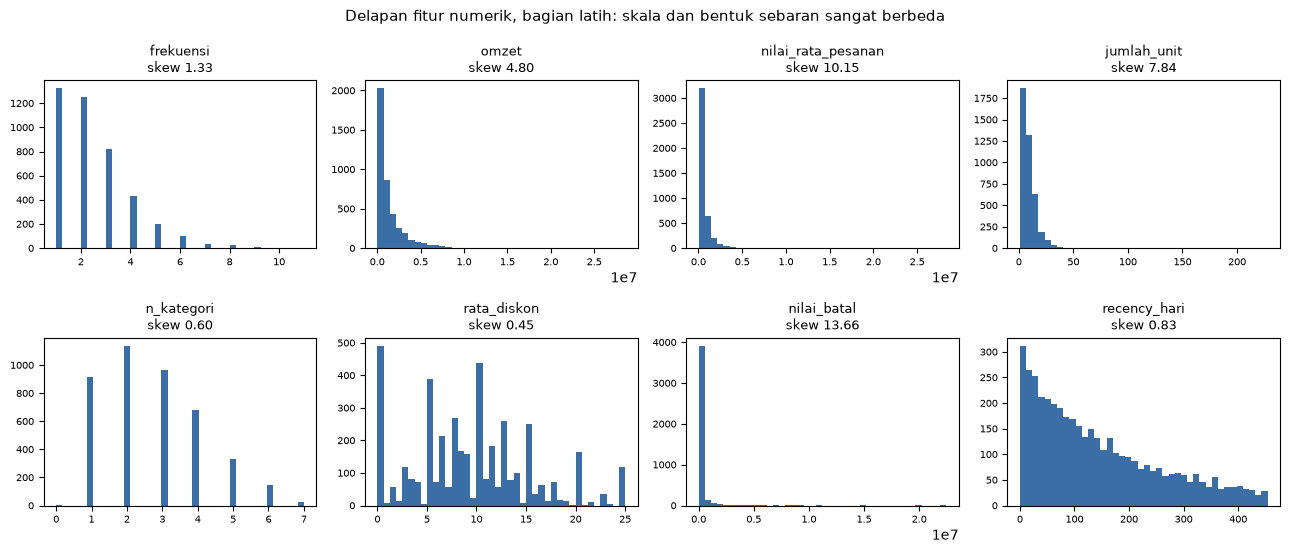

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
for ax, k in zip(axes.ravel(), NUMERIK):
    ax.hist(latih[k], bins=40, color="#3b6ea5")
    ax.set_title(f"{k}\nskew {latih[k].skew():.2f}", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 4))
fig.suptitle("Delapan fitur numerik, bagian latih: skala dan bentuk sebaran sangat berbeda", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "01_profil_fitur.png", dpi=110)
plt.show()

**Pembahasan Bagian A**

- **Waktu pesanan, bukan waktu baris.** 18 baris ber-`waktu_wib` kosong, tetapi 10 di antaranya
  milik pesanan yang baris lainnya berwaktu sah. Dengan `transform("min")` per pesanan, baris itu
  tetap bertempat; hanya 8 pesanan (8 baris) yang seluruh barisnya tanpa waktu dan tidak dapat
  ditempatkan di bagian mana pun. Menyaring `waktu_wib.notna()` per baris akan memotong 9 baris
  berstatus selesai dari pesanan yang sebenarnya utuh.
- **Populasi.** 411 baris pembeli tamu tidak memiliki `id_entitas`, jadi tidak dapat menjadi baris
  fitur. Bagian latih memuat 4.201 entitas, bagian uji 1.969; 1.679 entitas muncul di keduanya dan
  290 hanya di bagian uji. Kunci tabel fitur karena itu `(id_entitas, bagian)`, bukan `id_entitas`.
- **Empat definisi keliru, diukur.** Menghitung baris alih-alih pesanan mengubah frekuensi 2.712
  entitas dan membuatnya 1,53 kali terlalu besar. Memasukkan semua status menambah omzet 21,0% dan
  memunculkan 256 "pelanggan" yang tidak pernah menyelesaikan satu pesanan pun. Menambahkan
  `ongkir` ke `total_bayar` menghitung ongkir dua kali (+5,2%). Mengelompokkan menurut
  `id_pelanggan` menghasilkan 4.723 baris untuk 4.201 orang: 512 entitas berbelanja lewat lebih dari
  satu id, dan frekuensi rata-ratanya turun dari 2,43 menjadi 2,16.
- **Skala.** `omzet` sendirian menyumbang 75,5% ragam total delapan fitur; bersama
  `nilai_rata_pesanan` dan `nilai_batal` hampir 100%. Jarak Euclid pada fitur mentah praktis hanya
  mengukur rupiah. Kemencengan terbesar: `nilai_batal` 13,7, `nilai_rata_pesanan` 10,2,
  `jumlah_unit` 7,8, `omzet` 4,8. `nilai_batal` bernilai nol pada 3.237 dari 4.201 entitas (77%).

Tidak ada penskala yang dapat memperbaiki fitur yang dihitung pada butir yang salah; karena itu
definisi diperiksa lebih dulu, baru skalanya.

## Bagian B — Min-max, z-score, dan robust scaler

### B.1 Rumus buku, diterapkan manual

Setiap penskala adalah pasangan **(pusat, sebar)**; nilai hasil = `(x − pusat) / sebar`. Menyimpan
dua angka itu sama dengan menyimpan transformasinya.

In [11]:
def parameter_skala(x: pd.Series, cara: str) -> dict:
    """Pelajari (pusat, sebar) dari x. cara: 'minmax', 'zscore', atau 'robust'."""
    if cara == "minmax":
        pusat, sebar = x.min(), x.max() - x.min()
    elif cara == "zscore":
        pusat, sebar = x.mean(), x.std(ddof=0)
    elif cara == "robust":
        pusat, sebar = x.median(), x.quantile(.75) - x.quantile(.25)
    else:
        raise ValueError(cara)
    if sebar == 0:        # fitur tanpa sebaran menurut ukuran ini: jangan membagi dengan nol.
        sebar = 1.0       # scikit-learn melakukan hal yang sama, tanpa peringatan apa pun
    return {"skala": cara, "pusat": float(pusat), "sebar": float(sebar)}


def skalakan(x: pd.Series, par: dict) -> pd.Series:
    """Terapkan parameter yang SUDAH dipelajari; tidak menghitung ulang apa pun dari x."""
    return (x - par["pusat"]) / par["sebar"]


CARA = ["minmax", "zscore", "robust"]
PENSKALA = {"minmax": MinMaxScaler, "zscore": StandardScaler, "robust": RobustScaler}

In [12]:
selisih = {}
for cara in CARA:
    manual = pd.DataFrame({k: skalakan(latih[k], parameter_skala(latih[k], cara)) for k in NUMERIK})
    selisih[cara] = float(np.abs(manual.to_numpy() - PENSKALA[cara]().fit_transform(latih[NUMERIK])).max())
iqr = latih[NUMERIK].quantile(.75) - latih[NUMERIK].quantile(.25)
B["iqr_nol"] = iqr.index[iqr.eq(0)].tolist()
B["robust_batal_maks"] = float(skalakan(latih.nilai_batal, parameter_skala(latih.nilai_batal, "robust")).max())
B["robust_sb"] = {k: round(float(skalakan(latih[k], parameter_skala(latih[k], "robust")).std(ddof=0)), 2) for k in NUMERIK}
print("fitur ber-IQR 0:", B["iqr_nol"], "| nilai_batal hasil robust, maksimum:", angka(B["robust_batal_maks"], 0))
z1 = (latih[NUMERIK] - latih[NUMERIK].mean()) / latih[NUMERIK].std(ddof=1)
B["manual_vs_sklearn"] = selisih
B["ddof1_selisih_maks"] = float(np.abs(z1.to_numpy() - StandardScaler().fit_transform(latih[NUMERIK])).max())
B["ddof_faktor"] = float(np.sqrt((len(latih) - 1) / len(latih)))
print("selisih manual vs scikit-learn :", {k: f"{v:.1e}" for k, v in selisih.items()})
print(f"z-score ddof=1 vs StandardScaler: selisih maks {B['ddof1_selisih_maks']:.4f} (faktor {B['ddof_faktor']:.6f})")

fitur ber-IQR 0: ['nilai_batal'] | nilai_batal hasil robust, maksimum: 22.465.000
selisih manual vs scikit-learn : {'minmax': '1.1e-16', 'zscore': '0.0e+00', 'robust': '0.0e+00'}
z-score ddof=1 vs StandardScaler: selisih maks 0.0036 (faktor 0.999881)


### B.2 Pencilan sah dan tiga penskala

Pembelian grosir sah (Modul 3) dan tetap ada di data. Bandingkan parameter yang dipelajari dari
seluruh bagian latih dengan parameter yang dipelajari tanpa entitas ber-`ada_grosir`.

grosir_latih            : 53
ubah_tanpa_grosir       : {'minmax': {'pusat_persen': 0.0, 'sebar_persen': -20.96}, 'zscore': {'pusat_persen': -8.2, 'sebar_persen': -21.94}, 'robust': {'pusat_persen': -2.47, 'sebar_persen': -3.57}}
minmax_median           : 0.026497851265151952
minmax_bawah_01_persen  : 85.2654129969055
minmax_p99              : 0.31420582654900747
z_maks                  : 12.64339210312592
robust_maks             : 18.174789036436188
z_lebih_3_persen        : 1.4996429421566295
omzet_maks              : 28563550.0
omzet_maks_tanpa_grosir : 22581550.0
omzet_grosir_median     : 8122075.0


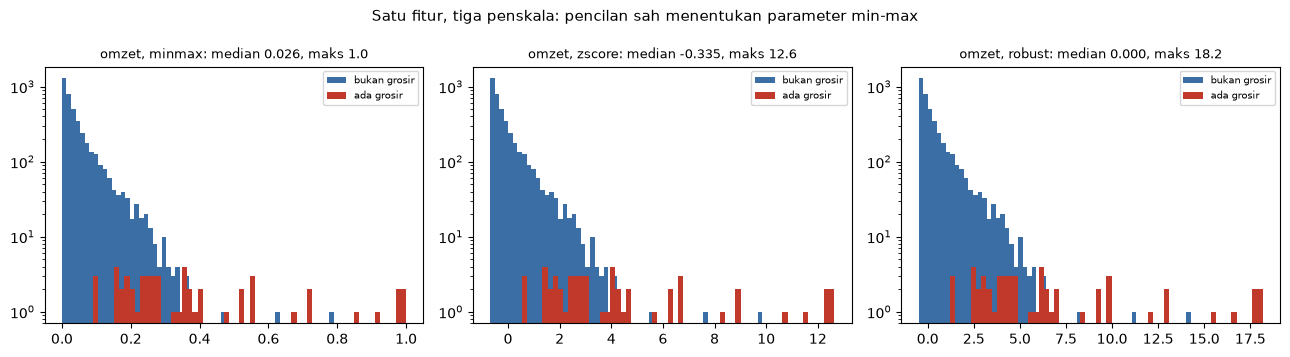

In [13]:
x, g = latih.omzet, latih.ada_grosir
par = {c: parameter_skala(x, c) for c in CARA}
par_tanpa = {c: parameter_skala(x[~g], c) for c in CARA}
B["grosir_latih"] = int(g.sum())
B["ubah_tanpa_grosir"] = {c: {"pusat_persen": round(100 * (par_tanpa[c]["pusat"] / par[c]["pusat"] - 1), 2)
                              if par[c]["pusat"] else 0.0,
                              "sebar_persen": round(100 * (par_tanpa[c]["sebar"] / par[c]["sebar"] - 1), 2)}
                          for c in CARA}
hasil = pd.DataFrame({c: skalakan(x, par[c]) for c in CARA})
B["minmax_median"] = float(hasil.minmax.median())
B["minmax_bawah_01_persen"] = float(100 * hasil.minmax.lt(0.1).mean())
B["minmax_p99"] = float(hasil.minmax.quantile(.99))
B["z_maks"], B["robust_maks"] = float(hasil.zscore.max()), float(hasil.robust.max())
B["z_lebih_3_persen"] = float(100 * hasil.zscore.abs().gt(3).mean())
B["omzet_maks"], B["omzet_maks_tanpa_grosir"] = float(x.max()), float(x[~g].max())
B["omzet_grosir_median"] = float(x[g].median())
for k in ["grosir_latih", "ubah_tanpa_grosir", "minmax_median", "minmax_bawah_01_persen", "minmax_p99", "z_maks",
          "robust_maks", "z_lebih_3_persen", "omzet_maks", "omzet_maks_tanpa_grosir", "omzet_grosir_median"]:
    print(f"{k:<24}: {B[k]}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, CARA):
    ax.hist(hasil[c][~g], bins=60, color="#3b6ea5", label="bukan grosir")
    ax.hist(hasil[c][g], bins=60, color="#c0392b", label="ada grosir")
    ax.set_yscale("log")
    ax.set_title(f"omzet, {c}: median {hasil[c].median():.3f}, maks {hasil[c].max():.1f}", fontsize=9)
    ax.legend(fontsize=7)
fig.suptitle("Satu fitur, tiga penskala: pencilan sah menentukan parameter min-max", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "02_tiga_penskala.png", dpi=110)
plt.show()

### B.3 Kebocoran: parameter dari seluruh data

Parameter dipelajari dari tiga dasar: bagian latih, bagian latih tanpa grosir, dan seluruh data
(latih + uji). Dasar ketiga adalah **kebocoran**: informasi bagian uji ikut menentukan transformasi.

In [14]:
DASAR = {"latih": latih, "latih_tanpa_grosir": latih[~latih.ada_grosir], "semua": fitur}
banding = pd.DataFrame([{"fitur": k, "skala": c, "dasar_fit": nama, "n": len(df),
                         **{m: parameter_skala(df[k], c)[m] for m in ("pusat", "sebar")}}
                        for k in NUMERIK for c in CARA for nama, df in DASAR.items()])
banding.to_csv(OUT / "perbandingan_skala_m05.csv", index=False)
banding[banding.fitur.eq("omzet")]

,fitur,skala,dasar_fit,n,pusat,sebar
9,omzet,minmax,latih,4201,2.35e+04,2.854e+07
10,omzet,minmax,latih_tanpa_grosir,4148,2.35e+04,2.256e+07
11,omzet,minmax,semua,6170,2.35e+04,2.854e+07
12,omzet,zscore,latih,4201,1.498e+06,2.141e+06
13,omzet,zscore,latih_tanpa_grosir,4148,1.375e+06,1.671e+06
14,omzet,zscore,semua,6170,1.277e+06,1.957e+06
15,omzet,robust,latih,4201,7.798e+05,1.529e+06
16,omzet,robust,latih_tanpa_grosir,4148,7.605e+05,1.474e+06
17,omzet,robust,semua,6170,6.073e+05,1.28e+06


In [15]:
lebar = banding[banding.skala.eq("zscore")].pivot(index="fitur", columns="dasar_fit", values=["pusat", "sebar"])
geser = pd.DataFrame({"pusat_persen": 100 * (lebar["pusat"]["semua"] / lebar["pusat"]["latih"] - 1),
                      "sebar_persen": 100 * (lebar["sebar"]["semua"] / lebar["sebar"]["latih"] - 1)}).loc[NUMERIK]
par_z = {k: parameter_skala(latih[k], "zscore") for k in NUMERIK}
par_z_bocor = {k: parameter_skala(fitur[k], "zscore") for k in NUMERIK}
z_uji = pd.DataFrame({k: skalakan(uji[k], par_z[k]) for k in NUMERIK})
z_uji_bocor = pd.DataFrame({k: skalakan(uji[k], par_z_bocor[k]) for k in NUMERIK})
geser["z_uji_rata"], geser["z_uji_sb"] = z_uji.mean(), z_uji.std(ddof=0)
geser["selisih_z_bocor_rata"] = (z_uji_bocor - z_uji).abs().mean()
par_mm = {k: parameter_skala(latih[k], "minmax") for k in NUMERIK}
mm_uji = pd.DataFrame({k: skalakan(uji[k], par_mm[k]) for k in NUMERIK})
geser["uji_di_luar_01"] = ((mm_uji < 0) | (mm_uji > 1)).sum()
B["geser"] = geser.round(3)
B["geser_pusat_maks"] = (geser.pusat_persen.abs().idxmax(), float(geser.pusat_persen.abs().max()))
B["uji_luar_01"] = int(geser.uji_di_luar_01.sum())
B["frek_median"] = {"latih": float(latih.frekuensi.median()), "uji": float(uji.frekuensi.median())}
B["frek_rata"] = {"latih": float(latih.frekuensi.mean()), "uji": float(uji.frekuensi.mean())}
B["lama_jendela_hari"] = {b: int((a[1] - a[0]).days + 1) for b, a in JENDELA.items()}
print("lama jendela (hari):", B["lama_jendela_hari"], "| rata-rata frekuensi:", B["frek_rata"])
geser.round(3)

lama jendela (hari): {'latih': 455, 'uji': 91} | rata-rata frekuensi: {'latih': 2.425374910735539, 'uji': 1.3118334179786695}


,pusat_persen,sebar_persen,z_uji_rata,z_uji_sb,selisih_z_bocor_rata,uji_di_luar_01
fitur,,,,,,
frekuensi,-14.65,-7.157,-0.764,0.413,0.204,0
omzet,-14.76,-8.585,-0.324,0.643,0.083,0
nilai_rata_pesanan,-0.405,2.25,-0.008,1.069,0.015,0
jumlah_unit,-15.62,-9.353,-0.301,0.616,0.075,0
n_kategori,-11.38,-3.455,-0.697,0.676,0.205,0
rata_diskon,-0.107,8.02,-0.005,1.234,0.076,0
nilai_batal,-25.68,-15.83,-0.172,0.258,0.033,0
recency_hari,-22.93,-6.96,-0.881,0.225,0.236,0


**Pembahasan Bagian B**

- **Manual = scikit-learn**, asalkan definisinya sama. Selisih terbesar tiga penskala di bawah
  10⁻¹⁵. `StandardScaler` memakai simpangan baku populasi (`ddof=0`); rumus buku (6.5) memakai
  simpangan baku sampel (`ddof=1`). Pada 4.201 baris selisihnya hanya faktor 0,999881 (z terbesar
  bergeser 0,0036), tetapi parameter yang disimpan harus menyebut pilihan itu.
- **Robust scaler diam-diam tidak menskalakan `nilai_batal`.** Kuartil pertama dan ketiganya
  sama-sama 0, sehingga IQR = 0. scikit-learn mengganti pembagi nol dengan 1 tanpa peringatan:
  kolom itu keluar dalam rupiah mentah (maksimum 22.465.000) dan simpangan bakunya 804.208, sementara
  tujuh fitur lain bersimpangan baku 0,7–2,1. Penskala yang "tahan pencilan" justru menghasilkan
  satu kolom yang menguasai seluruh jarak.
- **Pencilan sah.** 53 entitas grosir (omzet median Rp8,1 juta, maksimum Rp28,6 juta). Tanpa
  mereka, sebar min-max berubah −21,0%, simpangan baku z-score −21,9%, sedangkan IQR hanya −3,6%.
  Pada min-max, median hasil 0,026 dan 85,3% entitas berada di bawah 0,1: hampir seluruh pelanggan
  dimampatkan ke sepersepuluh rentang oleh dua nilai ujung. Pada z-score, nilai terbesar 12,6 dan
  1,5% entitas ber-|z| > 3.
- **Kebocoran.** Bila bagian uji ikut `fit`, pusat z-score bergeser sampai −25,7% (`nilai_batal`),
  −22,9% (`recency_hari`), −14,8% (`omzet`), −14,7% (`frekuensi`). Dengan parameter latih, z bagian
  uji tidak berpusat di 0: `recency_hari` −0,88, `frekuensi` −0,76. Itu **bukan galat**: jendela uji
  hanya 91 hari sedangkan jendela latih 455 hari, sehingga frekuensi rata-rata 1,31 lawan 2,43.
  Parameter yang di-fit ulang pada uji akan menghapus selisih itu dan menyembunyikan bahwa definisi
  fiturnya bergantung pada lama jendela.
- Tidak ada nilai uji yang keluar dari [0, 1] pada min-max karena maksimum latih kebetulan lebih
  besar; itu keberuntungan, bukan jaminan.

## Bagian C — Transformasi logaritma

### C.1 `log`, `log1p`, dan nilai nol

In [16]:
with np.errstate(divide="ignore"):
    ln_batal = np.log(latih.nilai_batal)          # logaritma biasa pada fitur yang memuat nol
print("nilai_batal bernilai 0 :", int(latih.nilai_batal.eq(0).sum()), "dari", len(latih))
print("hasil np.log tak hingga:", int(np.isinf(ln_batal).sum()))
print("hasil np.log1p terkecil:", float(np.log1p(latih.nilai_batal).min()))

nilai_batal bernilai 0 : 3237 dari 4201
hasil np.log tak hingga: 3237
hasil np.log1p terkecil: 0.0


In [17]:
AMBANG_SKEW = 1.0
log_tab = pd.DataFrame({"skew_asli": latih[NUMERIK].skew(), "skew_log1p": np.log1p(latih[NUMERIK]).skew(),
                        "n_nol": latih[NUMERIK].eq(0).sum()}).rename_axis("fitur")
log_tab["pakai_log"] = log_tab.skew_asli.gt(AMBANG_SKEW) & log_tab.skew_log1p.abs().lt(log_tab.skew_asli.abs())
log_tab["alasan"] = np.select(
    [log_tab.pakai_log, log_tab.skew_asli.abs().le(AMBANG_SKEW)],
    [f"skew > {AMBANG_SKEW:g} dan log1p memperkecil kemencengan",
     f"|skew| <= {AMBANG_SKEW:g}: sudah cukup simetris, log1p tidak diperlukan"],
    default="log1p tidak memperkecil kemencengan")
log_tab.reset_index().to_csv(OUT / "transformasi_log_m05.csv", index=False)
LOG_FITUR = [k for k in NUMERIK if log_tab.pakai_log[k]]
Z_FITUR = [k for k in NUMERIK if not log_tab.pakai_log[k]]
B["log_fitur"], B["z_fitur"] = LOG_FITUR, Z_FITUR
B["batal_nol"] = int(latih.nilai_batal.eq(0).sum())
B["batal_nol_persen"] = float(100 * latih.nilai_batal.eq(0).mean())
B["log_memperburuk"] = log_tab.index[log_tab.skew_log1p.abs().gt(log_tab.skew_asli.abs())].tolist()
B["skew_log"] = log_tab[["skew_asli", "skew_log1p"]].round(2).to_dict("index")
B["batal_positif_skew_log"] = float(np.log1p(latih.nilai_batal[latih.nilai_batal.gt(0)]).skew())
print("log1p lalu z-score:", LOG_FITUR)
print("z-score saja      :", Z_FITUR)
print("lebih menceng setelah log1p:", B["log_memperburuk"])
log_tab.round(2)

log1p lalu z-score: ['frekuensi', 'omzet', 'nilai_rata_pesanan', 'jumlah_unit', 'nilai_batal']
z-score saja      : ['n_kategori', 'rata_diskon', 'recency_hari']
lebih menceng setelah log1p: ['rata_diskon', 'recency_hari']


,skew_asli,skew_log1p,n_nol,pakai_log,alasan
fitur,,,,,
frekuensi,1.33,0.41,0,True,skew > 1 dan log1p memperkecil kemencengan
omzet,4.8,-0.17,0,True,skew > 1 dan log1p memperkecil kemencengan
nilai_rata_pesanan,10.15,0.17,0,True,skew > 1 dan log1p memperkecil kemencengan
jumlah_unit,7.84,0.41,0,True,skew > 1 dan log1p memperkecil kemencengan
n_kategori,0.6,-0.07,4,False,"|skew| <= 1: sudah cukup simetris, log1p tidak..."
rata_diskon,0.45,-1.25,491,False,"|skew| <= 1: sudah cukup simetris, log1p tidak..."
nilai_batal,13.66,1.33,3237,True,skew > 1 dan log1p memperkecil kemencengan
recency_hari,0.83,-1.08,23,False,"|skew| <= 1: sudah cukup simetris, log1p tidak..."


### C.2 Membaca dan mengembalikan skala log

In [18]:
rata_log = np.log1p(latih.omzet).mean()
print("rata-rata omzet (aritmetika)   :", angka(latih.omzet.mean(), 0))
print("median omzet                    :", angka(latih.omzet.median(), 0))
print("expm1(rata-rata log1p omzet)    :", angka(np.expm1(rata_log), 0))

rata-rata omzet (aritmetika)   : 1.497.737
median omzet                    : 779.750
expm1(rata-rata log1p omzet)    : 737.136


omzet_rata                  : 1497736.7888597953
omzet_median                : 779750.0
omzet_rata_geometrik        : 737136.2875046561
geometrik_vs_rata_persen    : -50.78332234425336
geometrik_vs_median_persen  : -5.4650480917401545
peringkat_berubah           : ['Rempah', 'Olahan Ikan', 'Tidak dikenal', 'Sayur dan Buah Segar']
z_mentah_maks               : 12.64339210312592
z_log_maks                  : 2.9099878816148697
z_mentah_min                : -0.6886677902120358
z_log_min                   : -2.7417903418786724
z_mentah_lebih3_persen      : 1.4996429421566295
z_log_lebih3_persen         : 0.0
z_log_grosir_median         : 1.9093507413597786


,n,aritmetika,geometrik,peringkat_aritmetika,peringkat_geometrik
kategori_favorit,,,,,
Kain Tenun,833,3.314e+06,2.594e+06,1,1
Kerajinan,1111,1.681e+06,1.282e+06,2,2
Kopi,807,1.179e+06,5.802e+05,3,3
Rempah,355,8.217e+05,3.004e+05,4,5
Olahan Ikan,418,4.826e+05,3.443e+05,5,4
Tidak dikenal,4,4.579e+05,2.261e+05,6,7
Sayur dan Buah Segar,335,3.869e+05,2.662e+05,7,6
Makanan Ringan,338,2.581e+05,1.746e+05,8,8


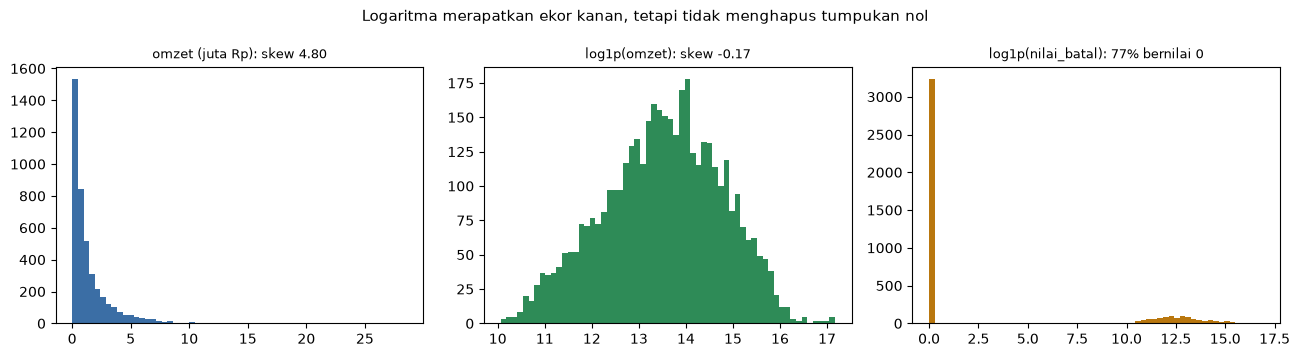

In [19]:
B["omzet_rata"], B["omzet_median"] = float(latih.omzet.mean()), float(latih.omzet.median())
B["omzet_rata_geometrik"] = float(np.expm1(rata_log))
B["geometrik_vs_rata_persen"] = float(100 * (B["omzet_rata_geometrik"] / B["omzet_rata"] - 1))
B["geometrik_vs_median_persen"] = float(100 * (B["omzet_rata_geometrik"] / B["omzet_median"] - 1))
per_kat = latih.groupby("kategori_favorit").omzet.agg(
    n="size", aritmetika="mean", geometrik=lambda s: np.expm1(np.log1p(s).mean())).sort_values("aritmetika", ascending=False)
per_kat["peringkat_aritmetika"] = per_kat.aritmetika.rank(ascending=False).astype(int)
per_kat["peringkat_geometrik"] = per_kat.geometrik.rank(ascending=False).astype(int)
B["peringkat_berubah"] = per_kat.index[per_kat.peringkat_aritmetika.ne(per_kat.peringkat_geometrik)].tolist()
z_mentah = skalakan(latih.omzet, parameter_skala(latih.omzet, "zscore"))
lo = np.log1p(latih.omzet)
z_log = skalakan(lo, parameter_skala(lo, "zscore"))
B["z_mentah_maks"], B["z_log_maks"] = float(z_mentah.max()), float(z_log.max())
B["z_mentah_min"], B["z_log_min"] = float(z_mentah.min()), float(z_log.min())
B["z_mentah_lebih3_persen"] = float(100 * z_mentah.abs().gt(3).mean())
B["z_log_lebih3_persen"] = float(100 * z_log.abs().gt(3).mean())
B["z_log_grosir_median"] = float(z_log[latih.ada_grosir].median())
B["kali_e"] = float(np.e)
for k in ["omzet_rata", "omzet_median", "omzet_rata_geometrik", "geometrik_vs_rata_persen", "geometrik_vs_median_persen",
          "peringkat_berubah", "z_mentah_maks", "z_log_maks", "z_mentah_min", "z_log_min", "z_mentah_lebih3_persen",
          "z_log_lebih3_persen", "z_log_grosir_median"]:
    print(f"{k:<28}: {B[k]}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(latih.omzet / 1e6, bins=60, color="#3b6ea5")
axes[0].set_title(f"omzet (juta Rp): skew {latih.omzet.skew():.2f}", fontsize=9)
axes[1].hist(lo, bins=60, color="#2e8b57")
axes[1].set_title(f"log1p(omzet): skew {lo.skew():.2f}", fontsize=9)
axes[2].hist(np.log1p(latih.nilai_batal), bins=60, color="#b9770e")
axes[2].set_title(f"log1p(nilai_batal): {B['batal_nol_persen']:.0f}% bernilai 0", fontsize=9)
fig.suptitle("Logaritma merapatkan ekor kanan, tetapi tidak menghapus tumpukan nol", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "03_log_omzet.png", dpi=110)
plt.show()
per_kat.round(0)

**Pembahasan Bagian C**

- **Nol.** `np.log` menghasilkan −∞ pada 3.237 entitas ber-`nilai_batal` 0; `log1p` memetakan 0 ke 0.
  Nilai negatif tidak ada pada fitur ini; bila ada, logaritma bukan alatnya.
- **Aturan tertulis**: `log1p` dipakai bila skew > 1 pada bagian latih **dan** `log1p` memperkecil
  kemencengan. Hasilnya `frekuensi` (1,33 → 0,41), `omzet` (4,80 → −0,17), `nilai_rata_pesanan`
  (10,15 → 0,17), `jumlah_unit` (7,84 → 0,41), dan `nilai_batal` (13,66 → 1,33).
- **Tidak semua fitur perlu log.** `rata_diskon` (0,45 → −1,25) dan `recency_hari` (0,83 → −1,08)
  justru menjadi menceng ke kiri; `n_kategori` sudah simetris. Ketiganya cukup z-score.
- **`nilai_batal` tidak menjadi simetris.** 77% nilainya tetap menumpuk di 0; logaritma hanya
  merapikan bagian positifnya (skew 0,41). Fitur ini pada dasarnya dua informasi: pernah batal atau
  tidak, dan berapa nilainya.
- **Rata-rata pada skala log bukan rata-rata rupiah.** `expm1` dari rata-rata `log1p(omzet)` adalah
  Rp737.136: rata-rata **geometrik**, 50,8% di bawah rata-rata aritmetika (Rp1.497.737) dan dekat
  median (Rp779.750). Urutan kategori pun berubah: menurut rata-rata aritmetika Rempah di atas
  Olahan Ikan, menurut rata-rata geometrik sebaliknya, karena omzet Rempah ditarik pembelian grosir.
  Selisih 1 pada skala log berarti kira-kira 2,72 kali lipat, bukan selisih rupiah yang tetap.
- **Setelah log, z-score tidak lagi dikuasai ekor.** z omzet mentah terentang −0,69 sampai 12,64
  (1,5% di atas 3); z dari `log1p(omzet)` terentang −2,74 sampai 2,91 dan tidak ada yang melewati 3.
  Entitas grosir tetap terlihat (median z = 1,91) tanpa menentukan parameter.

## Bagian D — Encoding dan pipeline yang dapat diterapkan ulang

### D.1 Label, ordinal, dan one-hot

In [20]:
le = LabelEncoder().fit(latih.provinsi)
kode_provinsi = dict(zip(le.classes_, range(len(le.classes_))))
print("LabelEncoder provinsi     :", kode_provinsi)
print("LabelEncoder kelompok_usia:", list(LabelEncoder().fit(latih.kelompok_usia).classes_))
print("urutan yang dimaksud      :", URUTAN_USIA)

LabelEncoder provinsi     : {'Aceh': 0, 'Bengkulu': 1, 'Jambi': 2, 'Kepulauan Bangka Belitung': 3, 'Kepulauan Riau': 4, 'Lampung': 5, 'Riau': 6, 'Sumatera Barat': 7, 'Sumatera Selatan': 8, 'Sumatera Utara': 9}
LabelEncoder kelompok_usia: ['25-34', '35-44', '45+', '<25', 'tidak_diketahui']
urutan yang dimaksud      : ['<25', '25-34', '35-44', '45+']


In [21]:
B["jarak_label"] = {"Aceh-Sumatera Utara": abs(kode_provinsi["Aceh"] - kode_provinsi["Sumatera Utara"]),
                    "Aceh-Bengkulu": abs(kode_provinsi["Aceh"] - kode_provinsi["Bengkulu"])}
B["label_usia"] = list(LabelEncoder().fit(latih.kelompok_usia).classes_)
oe = OrdinalEncoder(categories=[URUTAN_USIA], handle_unknown="use_encoded_value", unknown_value=np.nan)
kode_usia = oe.fit_transform(latih[["kelompok_usia"]])[:, 0]
B["usia_nan_latih"] = int(np.isnan(kode_usia).sum())
B["usia_median_kode"] = float(np.nanmedian(kode_usia))
oh = OneHotEncoder(sparse_output=False).fit(latih[["kanal"]])
M = oh.transform(latih[["kanal"]])
satu = np.ones((len(M), 1))
B["rank_onehot"] = (int(np.linalg.matrix_rank(np.hstack([satu, M]))), M.shape[1] + 1)
M1 = OneHotEncoder(sparse_output=False, drop="first").fit_transform(latih[["kanal"]])
B["rank_drop"] = (int(np.linalg.matrix_rank(np.hstack([satu, M1]))), M1.shape[1] + 1)
B["jarak_onehot"] = float(np.linalg.norm(np.eye(3)[0] - np.eye(3)[1]))
B["jarak_drop"] = {"acuan-lain": 1.0, "lain-lain": float(np.sqrt(2))}
B["kanal"] = latih.kanal.value_counts().to_dict()
for k in ["jarak_label", "label_usia", "usia_nan_latih", "usia_median_kode", "rank_onehot", "rank_drop",
          "jarak_onehot", "jarak_drop", "kanal"]:
    print(f"{k:<18}: {B[k]}")

jarak_label       : {'Aceh-Sumatera Utara': 9, 'Aceh-Bengkulu': 1}
label_usia        : ['25-34', '35-44', '45+', '<25', 'tidak_diketahui']
usia_nan_latih    : 192
usia_median_kode  : 2.0
rank_onehot       : (3, 4)
rank_drop         : (3, 3)
jarak_onehot      : 1.4142135623730951
jarak_drop        : {'acuan-lain': 1.0, 'lain-lain': 1.4142135623730951}
kanal             : {'web': 2053, 'app': 1662, 'keduanya': 486}


### D.2 Kategori yang baru muncul di bagian uji

In [22]:
baru = {k: sorted(set(uji[k]) - set(latih[k])) for k in KATEGORIK}
print({k: len(v) for k, v in baru.items()})

contoh = pd.DataFrame({"provinsi": ["Kalimantan Barat"]})      # wilayah layanan baru: tidak ada di data latih
try:
    OneHotEncoder(sparse_output=False).fit(latih[["provinsi"]]).transform(contoh)
except ValueError as e:
    print("handle_unknown='error' :", str(e)[:70])

{'kanal': 0, 'kategori_favorit': 0, 'metode_bayar_utama': 0, 'provinsi': 0, 'kelompok_usia': 0, 'produk_favorit': 50}
handle_unknown='error' : Found unknown categories ['Kalimantan Barat'] in column 0 during trans


In [23]:
B["kategori_baru"] = {k: len(v) for k, v in baru.items()}
B["uji_kena_kategori_baru"] = {k: int(uji[k].isin(v).sum()) for k, v in baru.items()}
abaikan = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(latih[["provinsi"]]).transform(contoh)
B["onehot_tak_dikenal"] = abaikan[0].tolist()
B["produk_latih"], B["produk_uji"] = int(latih.produk_favorit.nunique()), int(uji.produk_favorit.nunique())
print("kategori baru di uji      :", B["kategori_baru"])
print("entitas uji yang terkena  :", B["uji_kena_kategori_baru"])
print("one-hot provinsi tak dikenal (ignore):", B["onehot_tak_dikenal"])

kategori baru di uji      : {'kanal': 0, 'kategori_favorit': 0, 'metode_bayar_utama': 0, 'provinsi': 0, 'kelompok_usia': 0, 'produk_favorit': 50}
entitas uji yang terkena  : {'kanal': 0, 'kategori_favorit': 0, 'metode_bayar_utama': 0, 'provinsi': 0, 'kelompok_usia': 0, 'produk_favorit': 93}
one-hot provinsi tak dikenal (ignore): [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


### D.3 Kardinalitas tinggi: frequency dan target encoding

In [24]:
class FrekuensiEncoder(BaseEstimator, TransformerMixin):
    """Ganti kategori dengan porsi kemunculannya pada data fit; kategori tak dikenal -> 0."""

    def fit(self, X, y=None):
        s = pd.Series(np.asarray(X).ravel())
        self.peta_ = (s.value_counts() / len(s)).to_dict()
        return self

    def transform(self, X):
        s = pd.Series(np.asarray(X).ravel())
        return s.map(self.peta_).fillna(0.0).to_numpy(dtype=float).reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray([f"{k}_frek" for k in input_features])


y_latih, y_uji = np.log1p(latih.nilai_rata_pesanan), np.log1p(uji.nilai_rata_pesanan)   # target peragaan
rata_per_produk = y_latih.groupby(latih.produk_favorit).mean()
te_naif_latih = latih.produk_favorit.map(rata_per_produk)                 # memakai target baris itu sendiri
te_naif_uji = uji.produk_favorit.map(rata_per_produk).fillna(y_latih.mean())

produk_latih          : 807
produk_tunggal        : 139
produk_tunggal_persen : 17.224287484510533
produk_maks_n         : 29
te_naif_r_latih       : 0.8183326912284814
te_naif_r_uji         : 0.6873896933119709
te_naif_sama_target   : 139
te_silang_r_latih     : 0.6569704861655246
te_silang_r_uji       : 0.6903052253267903
frek_maks             : 0.006903118305165437
frek_uji_nol          : 93


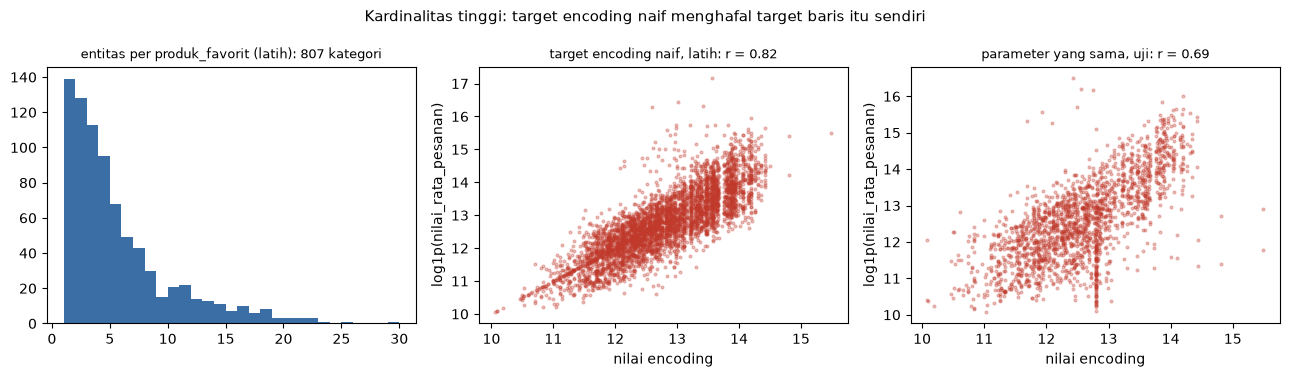

In [25]:
n_per_produk = latih.produk_favorit.value_counts()
B["produk_tunggal"] = int(n_per_produk.eq(1).sum())
B["produk_tunggal_persen"] = float(100 * n_per_produk.eq(1).mean())
B["produk_maks_n"] = int(n_per_produk.max())
B["te_naif_r_latih"] = float(np.corrcoef(te_naif_latih, y_latih)[0, 1])
B["te_naif_r_uji"] = float(np.corrcoef(te_naif_uji, y_uji)[0, 1])
tunggal = latih.produk_favorit.map(n_per_produk).eq(1)
B["te_naif_sama_target"] = int(np.isclose(te_naif_latih[tunggal], y_latih[tunggal]).sum())
te = TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=SEED))
te_silang_latih = te.fit_transform(latih[["produk_favorit"]], y_latih)[:, 0]
te_silang_uji = te.transform(uji[["produk_favorit"]])[:, 0]
B["te_silang_r_latih"] = float(np.corrcoef(te_silang_latih, y_latih)[0, 1])
B["te_silang_r_uji"] = float(np.corrcoef(te_silang_uji, y_uji)[0, 1])
frek = FrekuensiEncoder().fit(latih[["produk_favorit"]])
B["frek_maks"] = float(max(frek.peta_.values()))
B["frek_uji_nol"] = int((frek.transform(uji[["produk_favorit"]])[:, 0] == 0).sum())
for k in ["produk_latih", "produk_tunggal", "produk_tunggal_persen", "produk_maks_n", "te_naif_r_latih",
          "te_naif_r_uji", "te_naif_sama_target", "te_silang_r_latih", "te_silang_r_uji", "frek_maks", "frek_uji_nol"]:
    print(f"{k:<22}: {B[k]}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(n_per_produk, bins=range(1, n_per_produk.max() + 2), color="#3b6ea5")
axes[0].set_title(f"entitas per produk_favorit (latih): {B['produk_latih']} kategori", fontsize=9)
for ax, (a, b, judul) in zip(axes[1:], [(te_naif_latih, y_latih, f"target encoding naif, latih: r = {B['te_naif_r_latih']:.2f}"),
                                        (te_naif_uji, y_uji, f"parameter yang sama, uji: r = {B['te_naif_r_uji']:.2f}")]):
    ax.scatter(a, b, s=4, alpha=.3, color="#c0392b")
    ax.set_title(judul, fontsize=9)
    ax.set_xlabel("nilai encoding"); ax.set_ylabel("log1p(nilai_rata_pesanan)")
fig.suptitle("Kardinalitas tinggi: target encoding naif menghafal target baris itu sendiri", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "04_encoding.png", dpi=110)
plt.show()

### D.4 `ColumnTransformer` + `Pipeline`, dan parameternya sebagai JSON

Satu objek memuat seluruh keputusan Bagian B–D. `fit` dipanggil **sekali**, pada bagian latih.

In [26]:
ONEHOT = ["kanal", "kategori_favorit", "metode_bayar_utama", "provinsi"]


def slug(teks: str) -> str:
    return "_".join(str(teks).lower().replace("-", " ").split())

In [27]:
pra = ColumnTransformer([
    ("log_z", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                        ("z", StandardScaler())]), LOG_FITUR),
    ("z", StandardScaler(), Z_FITUR),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ONEHOT),
    ("ordinal", Pipeline([("kode", OrdinalEncoder(categories=[URUTAN_USIA], handle_unknown="use_encoded_value",
                                                  unknown_value=np.nan)),
                          ("isi", SimpleImputer(strategy="median", add_indicator=True)),
                          ("skala", MinMaxScaler())]), ["kelompok_usia"]),
    ("frek", FrekuensiEncoder(), ["produk_favorit"]),
])
pra.fit(latih)                                   # satu-satunya fit; bagian uji tidak ikut
X_latih, X_uji = pra.transform(latih), pra.transform(uji)

oh = pra.named_transformers_["onehot"]
NAMA_ONEHOT = {k: [f"t_{k}__{slug(v)}" for v in kat] for k, kat in zip(ONEHOT, oh.categories_)}
NAMA_T = ([f"t_{k}" for k in LOG_FITUR + Z_FITUR] + [n for k in ONEHOT for n in NAMA_ONEHOT[k]]
          + ["t_kelompok_usia", "t_usia_tidak_diketahui", "t_produk_favorit_frek"])
assert X_latih.shape[1] == len(NAMA_T) == len(set(NAMA_T))
print("matriks latih", X_latih.shape, "| matriks uji", X_uji.shape)

matriks latih (4201, 37) | matriks uji (1969, 37)


In [28]:
# Parameter diambil dari objek yang sudah di-fit, bukan dihitung ulang.
z_log = pra.named_transformers_["log_z"].named_steps["z"]
z_biasa = pra.named_transformers_["z"]
ordinal = pra.named_transformers_["ordinal"]
parameter = {
    "modul": 5, "seed": SEED, "dasar_fit": "latih",
    "jendela": {b: [str(a.date()), str(z.date())] for b, (a, z) in JENDELA.items()},
    "n_latih": len(latih), "n_uji": len(uji),
    "numerik": {
        **{k: {"log1p": True, "skala": "zscore", "pusat": float(m), "sebar": float(s), "kolom": f"t_{k}"}
           for k, m, s in zip(LOG_FITUR, z_log.mean_, z_log.scale_)},
        **{k: {"log1p": False, "skala": "zscore", "pusat": float(m), "sebar": float(s), "kolom": f"t_{k}"}
           for k, m, s in zip(Z_FITUR, z_biasa.mean_, z_biasa.scale_)},
    },
    "kategorik": {
        **{k: {"encoding": "onehot", "kategori": [str(v) for v in kat], "kolom": NAMA_ONEHOT[k],
               "tak_dikenal": "semua_nol"} for k, kat in zip(ONEHOT, oh.categories_)},
        "kelompok_usia": {"encoding": "ordinal", "urutan": URUTAN_USIA,
                          "isian_tak_diketahui": float(ordinal.named_steps["isi"].statistics_[0]),
                          "pembagi": float(ordinal.named_steps["skala"].data_range_[0]),
                          "kolom": ["t_kelompok_usia", "t_usia_tidak_diketahui"]},
        "produk_favorit": {"encoding": "frekuensi", "peta": {str(k): float(v) for k, v in
                                                             sorted(pra.named_transformers_["frek"].peta_.items())},
                           "tak_dikenal": 0.0, "kolom": "t_produk_favorit_frek"},
    },
    "urutan_kolom": NAMA_T,
}
(OUT / "parameter_transformasi_m05.json").write_text(json.dumps(parameter, indent=1, ensure_ascii=False), encoding="utf-8")
print({k: (round(v["pusat"], 4), round(v["sebar"], 4)) for k, v in parameter["numerik"].items()})

{'frekuensi': (1.1519, 0.3897), 'omzet': (13.5105, 1.2567), 'nilai_rata_pesanan': (12.7912, 1.0023), 'jumlah_unit': (2.089, 0.7573), 'nilai_batal': (2.9069, 5.3597), 'n_kategori': (2.7386, 1.402), 'rata_diskon': (9.2783, 6.0766), 'recency_hari': (141.7232, 115.6067)}


### D.5 Menyimpan `fitur_pelanggan_m05.parquet` dan kamus fitur

In [29]:
fitur_m05 = pd.concat([pd.concat([latih, uji], ignore_index=True),
                       pd.DataFrame(np.vstack([X_latih, X_uji]), columns=NAMA_T)], axis=1)
assert not fitur_m05.duplicated(["id_entitas", "bagian"]).any()
assert fitur_m05[fitur.columns].equals(pd.concat([latih, uji], ignore_index=True)), "kolom mentah berubah"
tl = fitur_m05[fitur_m05.bagian.eq("latih")]
t_num = [f"t_{k}" for k in NUMERIK]
assert np.allclose(tl[t_num].mean(), 0, atol=1e-9) and np.allclose(tl[t_num].std(ddof=0), 1, atol=1e-9)
assert all(np.allclose(tl[NAMA_ONEHOT[k]].sum(axis=1), 1) for k in ONEHOT)
fitur_m05.to_parquet(OUT / "fitur_pelanggan_m05.parquet", index=False)
tu = fitur_m05[fitur_m05.bagian.eq("uji")]
B["uji_t_rata"] = tu[t_num].mean().round(3).to_dict()
B["uji_t_sb"] = tu[t_num].std(ddof=0).round(3).to_dict()
B["uji_frek_nol"] = int(tu.t_produk_favorit_frek.eq(0).sum())
B["n_kolom_t"], B["n_kolom"] = len(NAMA_T), fitur_m05.shape[1]
print(fitur_m05.shape, "->", (OUT / "fitur_pelanggan_m05.parquet").name)
print("rata-rata kolom t_ numerik pada bagian uji:", B["uji_t_rata"])

(6170, 54) -> fitur_pelanggan_m05.parquet
rata-rata kolom t_ numerik pada bagian uji: {'t_frekuensi': -0.873, 't_omzet': -0.576, 't_nilai_rata_pesanan': -0.201, 't_jumlah_unit': -0.66, 't_n_kategori': -0.697, 't_rata_diskon': -0.005, 't_nilai_batal': -0.377, 't_recency_hari': -0.881}


In [30]:
DEFINISI = {
    "id_entitas": ("kunci", "pelanggan_m04.id_entitas", "entitas pelanggan (Modul 4); bersama `bagian` menjadi kunci"),
    "bagian": ("kunci", "transaksi_m04.waktu_wib", "latih: pesanan 2025-01-01 s.d. 2026-03-31; uji: 2026-04-01 s.d. 2026-06-30"),
    "frekuensi": ("mentah", "transaksi_m04.id_pesanan", "banyak pesanan berstatus selesai pada bagian itu"),
    "omzet": ("mentah", "transaksi_m04.total_bayar", "jumlah total_bayar baris berstatus selesai (rupiah, sudah memuat ongkir)"),
    "nilai_rata_pesanan": ("mentah", "omzet; frekuensi", "omzet dibagi frekuensi (rupiah per pesanan)"),
    "jumlah_unit": ("mentah", "transaksi_m04.jumlah", "jumlah unit pada baris berstatus selesai"),
    "n_kategori": ("mentah", "produk_m04.kategori", "banyak kategori produk berbeda yang dibeli (produk tak dikenal tidak dihitung)"),
    "rata_diskon": ("mentah", "transaksi_m04.diskon_persen", "rata-rata diskon_persen baris berstatus selesai (persen)"),
    "nilai_batal": ("mentah", "transaksi_m04.total_bayar", "jumlah total_bayar baris berstatus dibatalkan atau dikembalikan; 0 bila tidak ada"),
    "recency_hari": ("mentah", "transaksi_m04.waktu_wib", "hari dari pesanan selesai terakhir sampai akhir jendela bagian"),
    "ada_grosir": ("keterangan", "transaksi_m04.pembelian_grosir", "True bila ada baris pembelian grosir (Modul 3); tidak masuk matriks"),
    "kanal": ("mentah", "transaksi_m04.kanal", "web, app, atau keduanya"),
    "kategori_favorit": ("mentah", "produk_m04.kategori", "kategori dengan total belanja terbesar; `Tidak dikenal` bila semua produknya di luar katalog"),
    "metode_bayar_utama": ("mentah", "transaksi_m04.metode_bayar", "metode bayar dengan total belanja terbesar"),
    "provinsi": ("mentah", "pelanggan_m04.provinsi", "provinsi domisili entitas"),
    "kelompok_usia": ("mentah", "pelanggan_m04.tahun_lahir", "usia pada 2026: <25, 25-34, 35-44, 45+, atau tidak_diketahui"),
    "produk_favorit": ("mentah", "transaksi_m04.kode_produk", "kode produk dengan total belanja terbesar"),
}
baris_kamus = [{"kolom": k, "peran": p, "tipe": str(fitur_m05[k].dtype), "sumber": s, "definisi": d, "transformasi": "-"}
               for k, (p, s, d) in DEFINISI.items()]
for k, v in parameter["numerik"].items():
    baris_kamus.append({"kolom": v["kolom"], "peran": "transformasi", "tipe": "float64", "sumber": k,
                        "definisi": f"{k} pada skala model",
                        "transformasi": ("log1p lalu " if v["log1p"] else "") + "z-score (pusat dan sebar dari bagian latih)"})
for k, v in parameter["kategorik"].items():
    if v["encoding"] == "onehot":
        baris_kamus += [{"kolom": n, "peran": "transformasi", "tipe": "float64", "sumber": k,
                         "definisi": f"1 bila {k} = {kat}", "transformasi": "one-hot tanpa kolom dibuang; kategori tak dikenal -> semua 0"}
                        for n, kat in zip(v["kolom"], v["kategori"])]
baris_kamus += [
    {"kolom": "t_kelompok_usia", "peran": "transformasi", "tipe": "float64", "sumber": "kelompok_usia",
     "definisi": "kode urutan usia 0..3 dibagi 3", "transformasi": "ordinal urutan eksplisit; tidak_diketahui -> median kode bagian latih"},
    {"kolom": "t_usia_tidak_diketahui", "peran": "transformasi", "tipe": "float64", "sumber": "kelompok_usia",
     "definisi": "1 bila kelompok usia tidak diketahui", "transformasi": "indikator nilai isian"},
    {"kolom": "t_produk_favorit_frek", "peran": "transformasi", "tipe": "float64", "sumber": "produk_favorit",
     "definisi": "porsi entitas bagian latih yang produk favoritnya sama", "transformasi": "frequency encoding; kode tak dikenal -> 0"},
]
kamus = pd.DataFrame(baris_kamus).set_index("kolom").loc[list(fitur_m05.columns)].reset_index()
kamus.to_csv(OUT / "kamus_fitur_m05.csv", index=False)
print(kamus.peran.value_counts().to_dict())

{'transformasi': 37, 'mentah': 14, 'kunci': 2, 'keterangan': 1}


### D.6 Log keputusan

In [31]:
KOLOM_LOG = ["id", "modul", "sumber_kolom", "temuan", "bukti", "tindakan", "alasan",
             "baris_terdampak", "id_anomali"]


def catat_keputusan(baris: list[dict], path: Path = LOG) -> pd.DataFrame:
    """Tulis ulang baris log dengan id yang sama agar notebook aman dijalankan berulang."""
    lama_log = (pd.read_csv(path, dtype=str, keep_default_na=False) if path.exists()
                else pd.DataFrame(columns=KOLOM_LOG))
    baru = pd.DataFrame(baris, columns=KOLOM_LOG).astype(str)
    log = pd.concat([lama_log[~lama_log.id.isin(baru.id)], baru]).sort_values("id")
    log.to_csv(path, index=False)
    if path.parent != MODUL:
        shutil.copyfile(path, MODUL / path.name)   # salinan untuk ZIP tugas
    return log

In [32]:
ug = B["ubah_tanpa_grosir"]
log = catat_keputusan([
    {"id": "K-05-001", "modul": 5, "sumber_kolom": "transaksi_m04.waktu_wib;transaksi_m04.id_entitas",
     "temuan": "pembagian latih-uji berbasis waktu dan populasi fitur",
     "bukti": (f"waktu pesanan = waktu_wib paling awal per pesanan: {B['baris_nat_pulih']} dari {B['baris_nat']} baris NaT "
               f"tetap bertempat; {B['pesanan_tanpa_waktu']} pesanan ({B['baris_tanpa_waktu']} baris) tanpa waktu dan "
               f"{B['baris_tamu']} baris tamu di luar fitur; latih {B['n_latih']} entitas, uji {B['n_uji']}, "
               f"{B['n_keduanya']} di keduanya"),
     "tindakan": "bagian = latih bila waktu pesanan < 2026-04-01, uji sesudahnya; satu baris fitur per (id_entitas, bagian)",
     "alasan": "pembagian acak membocorkan masa depan; pesanan tanpa waktu tidak dapat ditempatkan; tamu tidak dapat disatukan menjadi entitas",
     "baris_terdampak": B["baris_tanpa_waktu"] + B["baris_tamu"], "id_anomali": "A-11"},
    {"id": "K-05-002", "modul": 5, "sumber_kolom": "transaksi_m04.id_pesanan;transaksi_m04.total_bayar;transaksi_m04.status",
     "temuan": "definisi fitur pada butir pesanan dan entitas",
     "bukti": (f"menghitung baris alih-alih pesanan mengubah frekuensi {B['frek_baris_beda']} entitas "
               f"(x{angka(B['frek_baris_rasio'], 2)}); semua status menambah omzet {angka(B['omzet_semua_status_persen'])}%; "
               f"menambahkan ongkir lagi menambah {angka(B['omzet_plus_ongkir_persen'])}%; per id_pelanggan ada "
               f"{B['n_id_pelanggan']} baris untuk {B['n_latih']} entitas"),
     "tindakan": "frekuensi = pesanan selesai unik; omzet = jumlah total_bayar baris selesai; batal dan kembali ke nilai_batal; kelompok menurut id_entitas",
     "alasan": "skala yang rapi tidak memperbaiki fitur yang dihitung pada butir yang salah",
     "baris_terdampak": B["frek_baris_beda"], "id_anomali": "-"},
    {"id": "K-05-003", "modul": 5, "sumber_kolom": "fitur.omzet",
     "temuan": "pembelian grosir sah menentukan parameter min-max",
     "bukti": (f"{B['grosir_latih']} entitas grosir; min-max: median {angka(B['minmax_median'], 3)}, "
               f"{angka(B['minmax_bawah_01_persen'])}% entitas di bawah 0,1; tanpa grosir sebar min-max berubah "
               f"{angka(ug['minmax']['sebar_persen'])}%, z-score {angka(ug['zscore']['sebar_persen'])}%, "
               f"robust {angka(ug['robust']['sebar_persen'])}%"),
     "tindakan": "min-max tidak dipakai untuk fitur berekor panjang; grosir tidak dibuang",
     "alasan": "minimum dan maksimum ditentukan dua entitas saja; pencilan sah tetap informasi; robust tidak dipakai karena IQR nilai_batal = 0",
     "baris_terdampak": 0, "id_anomali": "A-17"},
    {"id": "K-05-004", "modul": 5, "sumber_kolom": "fitur.*",
     "temuan": "parameter transformasi dipelajari dari bagian latih saja",
     "bukti": (f"fit pada seluruh data menggeser pusat z-score {B['geser_pusat_maks'][0]} "
               f"{angka(B['geser_pusat_maks'][1])}%; z-score ddof=1 berbeda dari StandardScaler sebesar faktor "
               f"{angka(B['ddof_faktor'], 6)}"),
     "tindakan": "fit sekali pada latih; uji hanya transform; simpangan baku ddof=0 mengikuti scikit-learn",
     "alasan": "bagian uji mewakili data yang belum ada saat parameter ditetapkan",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-05-005", "modul": 5, "sumber_kolom": "fitur." + ";fitur.".join(LOG_FITUR),
     "temuan": "fitur berekor kanan diberi log1p sebelum z-score",
     "bukti": (f"aturan skew > {AMBANG_SKEW:g}: " + ", ".join(f"{k} {angka(B['skew_log'][k]['skew_asli'], 2)} -> {angka(B['skew_log'][k]['skew_log1p'], 2)}"
                                                              for k in LOG_FITUR)
               + f"; nilai_batal bernilai 0 pada {B['batal_nol']} entitas sehingga log biasa tak hingga"),
     "tindakan": "log1p lalu z-score untuk " + ", ".join(LOG_FITUR),
     "alasan": "log1p terdefinisi pada nol; z-score pada skala log tidak lagi dikuasai ekor kanan",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-05-006", "modul": 5, "sumber_kolom": "fitur." + ";fitur.".join(Z_FITUR),
     "temuan": "fitur yang tidak diberi log1p",
     "bukti": "; ".join(f"{k} skew {angka(B['skew_log'][k]['skew_asli'], 2)} (log1p {angka(B['skew_log'][k]['skew_log1p'], 2)})" for k in Z_FITUR),
     "tindakan": "z-score saja",
     "alasan": "sebaran sudah cukup simetris; log1p justru membuatnya menceng ke kiri",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-05-007", "modul": 5, "sumber_kolom": "fitur.kanal;fitur.kategori_favorit;fitur.metode_bayar_utama;fitur.provinsi",
     "temuan": "kategori nominal berkardinalitas rendah",
     "bukti": (f"label encoding memberi jarak Aceh-Sumatera Utara {B['jarak_label']['Aceh-Sumatera Utara']} dan "
               f"Aceh-Bengkulu {B['jarak_label']['Aceh-Bengkulu']}; kategori baru di uji: "
               + ", ".join(f"{k} {B['kategori_baru'][k]}" for k in ONEHOT)),
     "tindakan": "one-hot tanpa kolom dibuang, handle_unknown=ignore",
     "alasan": "tidak ada urutan antarprovinsi; untuk jarak, membuang satu kolom membuat kategori acuan lebih dekat ke semua kategori lain",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-05-008", "modul": 5, "sumber_kolom": "fitur.kelompok_usia",
     "temuan": "kategori berurutan dengan nilai tidak diketahui",
     "bukti": (f"LabelEncoder mengurutkan {B['label_usia']}; tidak_diketahui pada {B['usia_nan_latih']} entitas latih"),
     "tindakan": "ordinal dengan urutan eksplisit dibagi 3; tidak_diketahui diisi median kode latih dan diberi kolom indikator",
     "alasan": "urutan abjad bukan urutan usia; tidak diketahui bukan kelompok usia kelima",
     "baris_terdampak": B["usia_nan_latih"], "id_anomali": "-"},
    {"id": "K-05-009", "modul": 5, "sumber_kolom": "fitur.produk_favorit",
     "temuan": "kategori berkardinalitas tinggi",
     "bukti": (f"{B['produk_latih']} kode pada latih, {B['produk_tunggal']} hanya dimiliki satu entitas; "
               f"{B['kategori_baru']['produk_favorit']} kode baru di uji ({B['uji_kena_kategori_baru']['produk_favorit']} entitas); "
               f"target encoding naif r latih {angka(B['te_naif_r_latih'], 2)} vs uji {angka(B['te_naif_r_uji'], 2)}"),
     "tindakan": "frequency encoding dari bagian latih, kode tak dikenal -> 0; target encoding tidak dipakai",
     "alasan": "one-hot menghasilkan ratusan kolom hampir kosong; target encoding naif menghafal target dan segmentasi tidak memiliki target",
     "baris_terdampak": B["uji_kena_kategori_baru"]["produk_favorit"], "id_anomali": "A-16"},
])
log[log.id.str.startswith("K-05-")][["id", "sumber_kolom", "baris_terdampak", "id_anomali"]]

,id,sumber_kolom,baris_terdampak,id_anomali
0,K-05-001,transaksi_m04.waktu_wib;transaksi_m04.id_entitas,419,A-11
1,K-05-002,transaksi_m04.id_pesanan;transaksi_m04.total_b...,2712,-
2,K-05-003,fitur.omzet,0,A-17
3,K-05-004,fitur.*,0,-
4,K-05-005,fitur.frekuensi;fitur.omzet;fitur.nilai_rata_p...,0,-
5,K-05-006,fitur.n_kategori;fitur.rata_diskon;fitur.recen...,0,-
6,K-05-007,fitur.kanal;fitur.kategori_favorit;fitur.metod...,0,-
7,K-05-008,fitur.kelompok_usia,192,-
8,K-05-009,fitur.produk_favorit,93,A-16


**Pembahasan Bagian D**

- **Label encoding menyisipkan jarak.** Kode abjad memberi Aceh–Sumatera Utara jarak 9 dan
  Aceh–Bengkulu jarak 1, padahal Aceh berbatasan dengan Sumatera Utara. Untuk `kelompok_usia`,
  `LabelEncoder` mengurutkan `25-34, 35-44, 45+, <25, tidak_diketahui`: kelompok termuda jatuh
  setelah yang tertua. Urutan harus dinyatakan eksplisit, dan `tidak_diketahui` (192 entitas latih)
  bukan kelompok usia kelima: ia diisi median kode latih (2 = `35-44`) dan diberi kolom indikator.
- **Dummy trap bergantung pada modelnya.** `[1 | one-hot kanal]` berpangkat 3 dari 4 kolom, jadi
  regresi dengan intersep perlu `drop="first"`. Untuk jarak, membuang satu kolom membuat kategori
  acuan berjarak 1 ke kategori lain sementara dua kategori lain berjarak √2. Segmentasi memakai
  jarak, sehingga tidak ada kolom yang dibuang.
- **Kategori baru.** Empat kolom berkardinalitas rendah dan `kelompok_usia` tidak memunculkan
  kategori baru di bagian uji, tetapi itu tidak menjamin bulan berikutnya. Dengan bawaan
  `handle_unknown="error"`, satu pelanggan dari provinsi baru menghentikan seluruh pipeline;
  dengan `"ignore"` sepuluh kolom provinsinya nol semua. `produk_favorit` berbeda: 50 kode di
  bagian uji tidak pernah muncul pada latih dan mengenai 93 entitas.
- **Kardinalitas tinggi.** 807 kode pada latih, 139 di antaranya hanya dimiliki satu entitas;
  one-hot berarti 807 kolom hampir kosong. Frequency encoding memberi satu kolom (porsi terbesar
  0,0069; kode baru → 0). Target encoding naif berkorelasi 0,82 dengan target pada latih tetapi
  0,69 pada uji: untuk 139 kode tunggal, nilai encoding **sama persis** dengan target baris itu.
  Dengan *cross fitting* korelasi latih turun ke 0,66, sejajar dengan uji (0,69). Segmentasi tidak
  memiliki target, jadi target encoding tidak masuk pipeline.
- **Pipeline dan parameter.** `fit` dipanggil sekali pada 4.201 baris latih; hasilnya 37 kolom `t_`
  (8 numerik, 26 one-hot, 2 usia, 1 frekuensi). Seluruh parameter (pusat, sebar, daftar kategori,
  urutan, isian, peta frekuensi) ditulis ke `parameter_transformasi_m05.json`, sehingga transformasi
  dapat diulang tanpa objek Python. Rata-rata kolom `t_` numerik pada bagian uji bukan 0
  (`t_recency_hari` −0,88, `t_frekuensi` −0,87, `t_n_kategori` −0,70, `t_jumlah_unit` −0,66,
  `t_omzet` −0,58): pergeseran itu dilaporkan, bukan dihapus dengan `fit` ulang.
- `t_produk_favorit_frek` berskala 0–0,007 di antara kolom berskala satuan, sehingga hampir tidak
  berbobot pada jarak. Itu disengaja untuk segmentasi ini dan dicatat di kamus fitur; model lain
  boleh menskalakannya lagi.

## Latihan Mandiri di Kelas

### Latihan 5.1 — Seberapa peka k-means dan tetangga terdekat terhadap skala?

Pakai delapan fitur numerik bagian latih dengan lima perlakuan: `tanpa_skala`, `minmax`, `zscore`,
`robust`, dan `acuan` (kolom `t_` numerik Bagian D). Untuk setiap perlakuan hitung: fitur yang
menyumbang ragam terbesar dan porsinya; ukuran klaster terkecil dan terbesar k-means (`k = 4`,
`n_init = 10`, `random_state = SEED`); *silhouette*; *adjusted Rand index* terhadap klaster
perlakuan `acuan`; dan rata-rata irisan 10 tetangga terdekat dengan tetangga pada `acuan`.

Simpan `keluaran/sensitivitas_skala_m05.csv` (kolom `skala`, `fitur_dominan`, `porsi_ragam_dominan`,
`klaster_terkecil`, `klaster_terbesar`, `silhouette`, `ari_acuan`, `irisan_tetangga`), grafik
`keluaran/05_sensitivitas_skala.png`, dan jawab di `latihan-sensitivitas.md` (120–250 kata):
perlakuan mana yang klasternya ditentukan satu fitur, mengapa *silhouette* tertinggi bukan berarti
segmentasi terbaik, dan perlakuan mana yang Anda pakai.

In [33]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

Bagian latih: fitur | fitur: ['frekuensi', 'omzet', 'nilai_rata_pesanan', 'jumlah_unit', 'n_kategori', 'rata_diskon', 'nilai_batal', 'recency_hari']
Bagian D    : fitur_m05 | kolom t_: ['t_frekuensi', 't_omzet', 't_nilai_rata_pesanan', 't_jumlah_unit', 't_nilai_batal', 't_n_kategori', 't_rata_diskon', 't_recency_hari', 't_kanal__app', 't_kanal__keduanya', 't_kanal__web', 't_kategori_favorit__kain_tenun', 't_kategori_favorit__kerajinan', 't_kategori_favorit__kopi', 't_kategori_favorit__makanan_ringan', 't_kategori_favorit__olahan_ikan', 't_kategori_favorit__rempah', 't_kategori_favorit__sayur_dan_buah_segar', 't_kategori_favorit__tidak_dikenal', 't_metode_bayar_utama__cod', 't_metode_bayar_utama__e_wallet', 't_metode_bayar_utama__kartu_kredit', 't_metode_bayar_utama__paylater', 't_metode_bayar_utama__transfer_bank', 't_provinsi__aceh', 't_provinsi__bengkulu', 't_provinsi__jambi', 't_provinsi__kepulauan_bangka_belitung', 't_provinsi__kepulauan_riau', 't_provinsi__lampung', 't_provinsi__r

,skala,fitur_dominan,porsi_ragam_dominan,klaster_terkecil,klaster_terbesar,silhouette,ari_acuan,irisan_tetangga
0,tanpa_skala,omzet,0.7415,21,4587,0.6064,0.0513,0.0295
1,minmax,rata_diskon,0.3589,1023,2082,0.3183,0.38,0.0661
2,zscore,frekuensi,0.125,52,3326,0.2584,0.2801,0.102
3,robust,nilai_batal,1,3,5922,0.9259,0.0009,0.1017
4,acuan,t_rata_diskon,0.1055,1049,2075,0.121,1,1


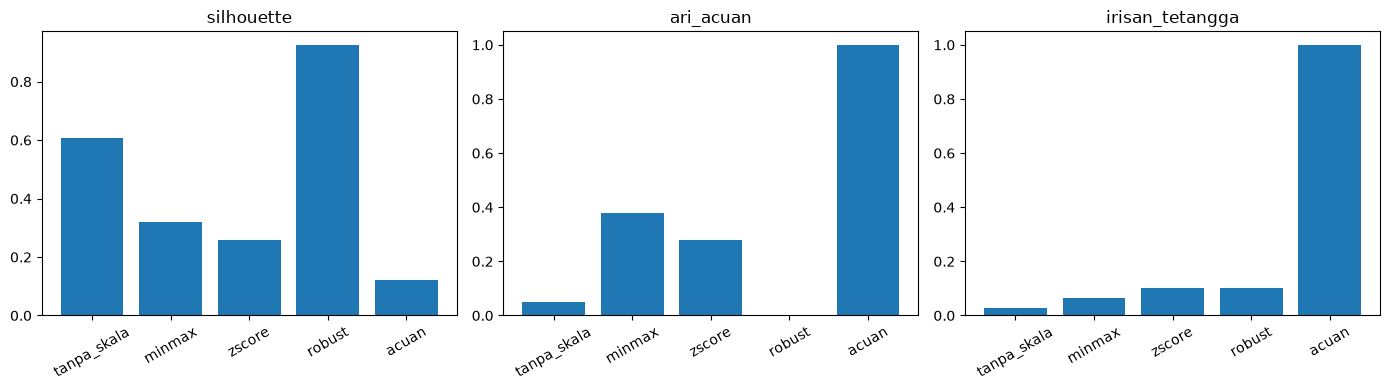

In [34]:
DF_LATIH_MANUAL = None 
DF_D_MANUAL     = None  
SEED_ = globals().get("SEED", 42)
OUT_  = Path(globals().get("OUT", "keluaran")); OUT_.mkdir(parents=True, exist_ok=True)

#  deteksi DataFrame (karena nama variabel notebookmu tidak kelihatan)
dfs = {n: o for n, o in list(globals().items())
       if isinstance(o, pd.DataFrame) and not n.startswith("_")}
kol_t   = lambda d: [c for c in d.columns if str(c).startswith("t_") and pd.api.types.is_numeric_dtype(d[c])]
kol_num = lambda d: [c for c in d.columns if pd.api.types.is_numeric_dtype(d[c]) and not str(c).startswith("t_")]

if DF_D_MANUAL is not None:
    DF_D, nama_d = DF_D_MANUAL, "manual"
else:
    cand = {n: o for n, o in dfs.items() if kol_t(o)}
    if not cand:
        raise RuntimeError("Tidak ada DataFrame berkolom 't_'. Jalankan sel Bagian D dulu (data acuan harus ada).")
    nama_d = max(cand, key=lambda n: len(kol_t(cand[n]))); DF_D = cand[nama_d]

if DF_LATIH_MANUAL is not None:
    DF_LATIH, nama_l = DF_LATIH_MANUAL, "manual"
else:
    cand = {n: o for n, o in dfs.items()
            if n != nama_d and len(kol_num(o)) >= 8 and len(o) == len(DF_D)}
    if not cand:
        raise RuntimeError("Bagian latih tidak ketemu. Isi DF_LATIH_MANUAL. DataFrame yang ada: "
                           + ", ".join(f"{n}{o.shape}" for n, o in dfs.items()))
    nama_l = next(iter(cand)); DF_LATIH = cand[nama_l]

FITUR_NUM = kol_num(DF_LATIH)[:8]
T_COLS = kol_t(DF_D)
print(f"Bagian latih: {nama_l} | fitur: {FITUR_NUM}")
print(f"Bagian D    : {nama_d} | kolom t_: {T_COLS}\n")

# TODO: lima matriks (tanpa_skala, minmax, zscore, robust, acuan) dari delapan fitur numerik latih
X = DF_LATIH[FITUR_NUM].astype(float)
acuan = DF_D[T_COLS].astype(float).copy()
if not X.index.equals(acuan.index):
    acuan.index = X.index        
ok = X.notna().all(axis=1) & acuan.notna().all(axis=1)
X, acuan = X[ok], acuan[ok]

def skala(X, metode):
    try:    
        h = skalakan(X, parameter_skala(X, metode))
        return pd.DataFrame(np.asarray(h), index=X.index, columns=X.columns)
    except Exception as e:
        print(f"[info] fungsi kelas gagal untuk '{metode}' ({type(e).__name__}); pakai versi manual")
        if metode == "minmax": return (X - X.min()) / (X.max() - X.min()).replace(0, 1)
        if metode == "zscore": return (X - X.mean()) / X.std(ddof=0).replace(0, 1)
        if metode == "robust":
            iqr = (X.quantile(.75) - X.quantile(.25)).replace(0, 1)
            return (X - X.median()) / iqr

matriks = {
    "tanpa_skala": X,
    "minmax": skala(X, "minmax"),
    "zscore": skala(X, "zscore"),
    "robust": skala(X, "robust"),
    "acuan":  acuan,
}

# TODO: per matriks: fitur dominan + porsi ragam, KMeans(k=4), ukuran klaster, silhouette,
#       ARI terhadap acuan, irisan 10 tetangga terdekat terhadap acuan
def klaster(A):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED_).fit_predict(A)

def tetangga(A, k=10):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(A)
    return nn.kneighbors(A, return_distance=False)[:, 1:]    # buang diri sendiri

lab_acuan = klaster(acuan.values)
tet_acuan = tetangga(acuan.values)

baris = []
for nama, M in matriks.items():
    A = M.values
    ragam = M.var(axis=0, ddof=0)
    porsi = ragam / ragam.sum()
    lab = klaster(A)
    ukuran = np.bincount(lab)
    tet = tetangga(A)
    irisan = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(tet, tet_acuan)])
    baris.append({
        "skala": nama,
        "fitur_dominan": porsi.idxmax(),
        "porsi_ragam_dominan": round(float(porsi.max()), 4),
        "klaster_terkecil": int(ukuran.min()),
        "klaster_terbesar": int(ukuran.max()),
        "silhouette": round(float(silhouette_score(A, lab)), 4),
        "ari_acuan": round(float(adjusted_rand_score(lab_acuan, lab)), 4),
        "irisan_tetangga": round(float(irisan), 4),
    })
hasil_skala = pd.DataFrame(baris)

# TODO: simpan OUT / "sensitivitas_skala_m05.csv" dan OUT / "05_sensitivitas_skala.png"
hasil_skala.to_csv(OUT_ / "sensitivitas_skala_m05.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, kol in zip(ax, ["silhouette", "ari_acuan", "irisan_tetangga"]):
    a.bar(hasil_skala["skala"], hasil_skala[kol])
    a.set_title(kol); a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(OUT_ / "05_sensitivitas_skala.png", dpi=150)
plt.show()

print("Tersimpan di:", OUT_.resolve())
hasil_skala

### Latihan 5.2 — Label atau one-hot, untuk model linear dan pohon

Prediksi `log1p(nilai_rata_pesanan)` dari empat kolom kategorik (`kanal`, `kategori_favorit`,
`metode_bayar_utama`, `provinsi`) dengan dua encoding (label menurut abjad, one-hot) dan dua model
(`LinearRegression`, `DecisionTreeRegressor(max_depth=8, random_state=SEED)`). Encoder dan model
di-`fit` pada bagian latih; R² dihitung pada latih dan uji.

Simpan `keluaran/encoding_model_m05.csv` (kolom `encoding`, `model`, `n_kolom`, `r2_latih`,
`r2_uji`) dan jawab di `latihan-encoding.md` (120–250 kata): kombinasi mana yang paling rugi,
mengapa pohon hampir tidak terpengaruh, dan apa akibatnya bagi pilihan encoding di Bagian D.

In [35]:
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

In [36]:
DF_LATIH_MANUAL = None  
DF_UJI_MANUAL   = None   

SEED_ = globals().get("SEED", 42)
OUT_  = Path(globals().get("OUT", "keluaran")); OUT_.mkdir(parents=True, exist_ok=True)

KAT, TARGET = ["kanal", "kategori_favorit", "metode_bayar_utama", "provinsi"], "nilai_rata_pesanan"

#  deteksi DataFrame latih dan uji 
if DF_LATIH_MANUAL is not None and DF_UJI_MANUAL is not None:
    DF_LATIH, DF_UJI = DF_LATIH_MANUAL, DF_UJI_MANUAL
    nama_l = nama_u = "manual"
else:
    dfs = {n: o for n, o in list(globals().items())
           if isinstance(o, pd.DataFrame) and not n.startswith("_")
           and TARGET in o.columns and all(k in o.columns for k in KAT)}
    if len(dfs) < 2:
        raise RuntimeError("DataFrame latih/uji tidak ketemu. Isi DF_LATIH_MANUAL dan DF_UJI_MANUAL. "
                           "Kandidat: " + ", ".join(f"{n}{o.shape}" for n, o in dfs.items()))
    urut = sorted(dfs.items(), key=lambda kv: -len(kv[1]))   
    (nama_l, DF_LATIH), (nama_u, DF_UJI) = urut[0], urut[1]
print(f"Latih: {nama_l} {DF_LATIH.shape} | Uji: {nama_u} {DF_UJI.shape}")
print("Pastikan latih lebih besar dari uji; kalau terbalik, isi variabel MANUAL.\n")

# TODO: dua encoding x dua model, fit pada latih, R2 pada latih dan uji
y_latih_log = np.log1p(DF_LATIH[TARGET])
y_uji_log   = np.log1p(DF_UJI[TARGET])

encoders = {
    "label":  OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "onehot": OneHotEncoder(handle_unknown="ignore", sparse_output=False),
}

baris = []
for en_nama, enc in encoders.items():
    enc.fit(DF_LATIH[KAT])                       
    Xl = enc.transform(DF_LATIH[KAT])
    Xu = enc.transform(DF_UJI[KAT])
    for m_nama, model in {
        "LinearRegression": LinearRegression(),
        "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=8, random_state=SEED_),
    }.items():
        model.fit(Xl, y_latih_log)               
        baris.append({
            "encoding": en_nama,
            "model": m_nama,
            "n_kolom": int(Xl.shape[1]),
            "r2_latih": round(float(r2_score(y_latih_log, model.predict(Xl))), 4),
            "r2_uji":   round(float(r2_score(y_uji_log,   model.predict(Xu))), 4),
        })
hasil_enc = pd.DataFrame(baris)

# TODO: simpan OUT / "encoding_model_m05.csv"
hasil_enc.to_csv(OUT_ / "encoding_model_m05.csv", index=False)
print("Tersimpan di:", (OUT_ / "encoding_model_m05.csv").resolve())
hasil_enc

Latih: fitur (6170, 17) | Uji: fitur_m05 (6170, 54)
Pastikan latih lebih besar dari uji; kalau terbalik, isi variabel MANUAL.

Tersimpan di: C:\Users\HP\workbench-workspace\data-wrangling\dw-module-05\keluaran\encoding_model_m05.csv


,encoding,model,n_kolom,r2_latih,r2_uji
0,label,LinearRegression,4,0.3914,0.3914
1,label,DecisionTreeRegressor,4,0.5424,0.5424
2,onehot,LinearRegression,26,0.5176,0.5176
3,onehot,DecisionTreeRegressor,26,0.5395,0.5395


## Tugas Individu

Dikerjakan di luar sesi. Folder `dw-module-05/` (notebook, keluaran, laporan, jawaban latihan, dan
salinan `log-keputusan.csv` yang ditulis otomatis oleh `catat_keputusan()`) dikompres menjadi
**`dw-module-05.zip`** dan diunggah ke tugas *Tugas Individu — Modul 05*; empat pertanyaan analisis
dijawab langsung pada formulir tugas yang sama.

**1. Menerapkan ulang tanpa `fit`.** Tulis fungsi `terapkan_parameter(df, parameter)` yang **hanya**
membaca `keluaran/parameter_transformasi_m05.json` (tanpa objek scikit-learn, tanpa menghitung
statistik apa pun dari `df`) dan menghasilkan seluruh kolom `t_` sesuai `urutan_kolom`. Buktikan
hasilnya sama dengan kolom `t_` pada `fitur_pelanggan_m05.parquet` untuk bagian latih dan uji
(selisih mutlak terbesar per kolom), lalu terapkan pada tiga pelanggan rekaan pada naskah (Tabel 5.6:
provinsi baru, produk favorit baru, usia tidak diketahui dengan omzet sangat besar) dan periksa bahwa
tidak ada galat maupun `NaN`. Simpan `keluaran/verifikasi_penerapan_m05.csv` (kolom `kolom`, `bagian`,
`n`, `selisih_maks`, `lulus`).

In [37]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

In [38]:
# TODO: par = json.loads((OUT / "parameter_transformasi_m05.json").read_text())
# TODO: def terapkan_parameter(df, par) -> DataFrame kolom t_ (numerik, one-hot, ordinal, frekuensi)
# TODO: bandingkan dengan fitur_pelanggan_m05.parquet per kolom dan per bagian
# TODO: tiga pelanggan rekaan Tabel 5.6 -> tanpa galat, tanpa NaN
# TODO: simpan OUT / "verifikasi_penerapan_m05.csv"

**2. Laporan pergeseran.** Bandingkan sebaran setiap kolom `t_` numerik pada bagian latih dan uji.
Simpan `keluaran/pergeseran_m05.csv` (kolom `kolom`, `rata_latih`, `sb_latih`, `rata_uji`, `sb_uji`,
`uji_di_luar_rentang_latih_persen`) dan grafik `keluaran/06_pergeseran.png`. Jelaskan di laporan
pergeseran mana yang berasal dari **definisi fitur** dan mana yang berasal dari **perilaku pelanggan**.

In [39]:
# TODO: tabel pergeseran latih vs uji untuk kolom t_ numerik -> OUT / "pergeseran_m05.csv"
# TODO: grafik 06 -> OUT / "06_pergeseran.png"

**3. Mengukur kebocoran.** Bangun pipeline pembanding yang di-`fit` pada **seluruh** data, lalu
bandingkan dengan pipeline Bagian D: parameter numerik (pusat, sebar) dan segmen k-means (`k = 4`,
dilatih pada matriks latih masing-masing) yang diterima entitas bagian uji. Simpan
`keluaran/kebocoran_m05.csv` (kolom `ukuran`, `fit_latih`, `fit_semua`, `selisih_persen`).

In [40]:
# TODO: pipeline pembanding fit pada seluruh data; tabel parameter dan segmen uji
# TODO: simpan OUT / "kebocoran_m05.csv"

**4. Log dan laporan.** Tambahkan keputusan Latihan dan Tugas ke log (sekurang-kurangnya **sebelas**
baris `K-05-*` seluruhnya), lalu tulis `laporan.md` (400–600 kata) dengan templat
`template-laporan.md`. Pertanyaan analisis dijawab pada formulir tugas di Learn.

In [41]:
# TODO: catat_keputusan([...]) untuk keputusan Latihan 5.1, pergeseran, dan kebocoran